# Statistical analysis: programming capacity and COVID-19 resilience
**Question.** Were EU NUTS 2 regions with *excess programming capacity* (more Stack Overflow programmers than expected from population and income) more resilient to COVID-19 — a smaller employment drop in 2020 (**H1a, shock**) and/or a stronger recovery by 2022 (**H1b, recovery**)? H0: no difference.

**This notebook is the whole statistical part, start to finish.** It starts from the master table v3 and ends with the reading of the answer. It follows *Group Guide v3* (13 Nov 2026), Steps 8–12.

### Ground rules (fixed before any result was seen)
- Nothing in the fixed decisions below changes after z is first compared with the outcomes. Any later change is reported as a deviation, with a reason.
- Outcomes are **not** z-scored. Only X (programming capacity) has a z. Outcomes stay in percentage points.
- The regression uses the **continuous** z. The excess/deficit groups are only for description.

### Roadmap (we build one section at a time)
| # | Section | Guide step | Status |
|---|---|---|---|
| 0 | Setup and fixed decisions | – | done |
| 1 | Load the master table and check it | Step 7 | done |
| 2 | Descriptives (outcomes, z, group averages, platform agreement) | Step 8 | done |
| 3 | Main regressions: shock, recovery A (primary), recovery B (secondary) | Step 9 | done |
| 4 | Wild cluster bootstrap-t, 95% intervals, Holm | Step 10 | done |
| 5 | Smallest detectable effect vs 1 pp margin | Step 11 | done |
| 6 | Reading the answer (fixed rule) | Step 12 | done |
| 7 | Final results table and figures | – | part of Section 6 (6c table, 6d plot) |

**Helper code and checks.** The helper code sits in the *Helper code* block right after Part 1 (you can skip it). *Appendix A* (at the end) explains the bootstrap engine in plain words and *Appendix B* shows all the checks.

## 0. Setup and fixed decisions
All the numbers decided on 13 Nov 2026 live in one place here, so they cannot drift later in the script.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# ---- Fixed statistical decisions (Guide v3, Section 7). Do not change after results. ----
MARGIN_PP   = 1.0      # equivalence margin m: 1 percentage point per 1 SD of z
ALPHA       = 0.05     # two-sided test level; gives the 95% interval
N_BOOT      = 9_999    # wild cluster bootstrap draws
SEED        = 42       # fixed seed for the bootstrap
YEARS       = (2019, 2020, 2022)   # 2021 is never used (series break)
SD_FACTOR   = 2.8      # smallest detectable effect = 2.8 * SE (80% power, 5% test); ~2.9 with ~22 clusters

# ---- Where the master table is. The file sits next to this notebook, so this works
# ---- whatever folder the kernel was started in.
_NAME = "master_table_v3_240_units.csv"
_candidates = [Path(_NAME), Path("data/data_processed") / _NAME, Path("data_processed") / _NAME]
MASTER_PATH = next((p for p in _candidates if p.exists()), _candidates[0])
print("Master table found:", MASTER_PATH.exists(), "->", MASTER_PATH.resolve())

Master table found: True -> D:\D Drive\Nova Final Thesis-Project\project csv's and dataset\Data_for_new_question\data\data_processed\master_table_v3_240_units.csv


## 1. Load the master table and check it
One row per analysis unit (240 NUTS 2 units, 2021 map; NL31+NL33 and PT16+PT18 merged, PT17 kept).

**Key columns**
- `z_so`: excess score for Stack Overflow (X). `z_github`: same for GitHub, used only for the rank-agreement check.
- `group_so`: excess (z > 0) or deficit (z < 0). Description only.
- `emp_2019`, `emp_2020`, `emp_2022`: employment rate 15–64 (%).
- `shock` = emp_2020 − emp_2019, `recovery` = emp_2022 − emp_2020, `net` = emp_2022 − emp_2019 (reference only). All in percentage points.
- `ln_pop`, `ln_gdp`: logs of 2019 population and GDP per inhabitant (PPS). These are the controls.
- `flag_emp_*`: Eurostat flags (series breaks etc.). Kept, never changed.

In [2]:
# Load the master table once: every later section reads from this one table, so nothing can drift between sections.
master = pd.read_csv(MASTER_PATH, index_col="analysis_unit")
print(master.shape)
master.head()

(240, 20)


,country_code,z_so,z_github,group_so,so_active_2019,github_contributors,population_2019,gdp_pps_per_inhabitant_2019,ln_pop,ln_gdp,emp_2019,emp_2020,emp_2022,shock,recovery,net,flag_emp_2019,flag_emp_2020,flag_emp_2022,missing_reason
analysis_unit,,,,,,,,,,,,,,,,,,,,
AT11,AT,-1.5798,-1.5363,deficit,4,5.0,293433,27200,12.5894,10.2110,71.9,72.0,73.3,0.1,1.3,1.4,NaN,NaN,NaN,NaN
AT12,AT,-1.8434,-1.4447,deficit,42,67.0,1677542,33100,14.3328,10.4073,74.4,74.1,74.7,-0.3,0.6,0.3,NaN,NaN,NaN,NaN
AT13,AT,1.8907,1.1606,excess,1249,1177.0,1897491,45600,14.4560,10.7277,67.1,65.5,67.8,-1.6,2.3,0.7,NaN,NaN,NaN,NaN
AT21,AT,-0.2750,-0.4193,deficit,34,42.0,560939,34100,13.2374,10.4371,72.2,70.2,72.5,-2.0,2.3,0.3,NaN,NaN,NaN,NaN
AT22,AT,0.2298,0.4196,excess,150,250.0,1243052,36200,14.0331,10.4968,74.7,73.3,74.7,-1.4,1.4,0.0,NaN,NaN,NaN,NaN


### 1a. Integrity checks
These `assert`s stop the script if the table is not the one the Guide describes. Expected numbers come from the Guide v3 and the handover note. If one fails, **stop and find out why** — do not edit the data to make it pass.

*You can skip the code; the line "All integrity checks passed." is the result.*

In [3]:
assert master.shape[0] == 240,               "expected 240 analysis units"
assert master.index.is_unique,               "analysis_unit must be unique"

# Estimation sample: units that have a Stack Overflow z (count > 0)
model = master[master["z_so"].notna()].copy()
assert len(model) == 234,                    "expected 234 units with a Stack Overflow z"

# z should be standardised (mean 0, sd 1 with n-1) on that sample
assert abs(model["z_so"].mean()) < 1e-3,     "z_so mean should be ~0"
assert abs(model["z_so"].std(ddof=1) - 1) < 1e-3, "z_so sd (n-1) should be ~1"

# Groups: zero line, not the median
assert (model["z_so"] > 0).sum() == 111 and (model["z_so"] < 0).sum() == 123, "expected 111 excess / 123 deficit"

# Outcomes are in the table and consistent with each other
chk = master[["emp_2019", "emp_2020", "emp_2022", "shock", "recovery", "net"]].dropna()
assert np.allclose(chk["shock"],    chk["emp_2020"] - chk["emp_2019"], atol=1e-3)
assert np.allclose(chk["recovery"], chk["emp_2022"] - chk["emp_2020"], atol=1e-3)
assert np.allclose(chk["net"],      chk["emp_2022"] - chk["emp_2019"], atol=1e-3)

# Every model unit has what the regressions need
need = ["z_so", "ln_pop", "ln_gdp", "country_code", "shock", "recovery"]
assert model[need].notna().all().all(),      "model units must have z, controls, country, shock and recovery"

# Countries that can contribute (country effects need >= 2 regions)
n_per_country = model["country_code"].value_counts()
n_clusters = int((n_per_country >= 2).sum())
assert n_clusters == 22,                     "expected 22 countries with 2+ regions in the model"
print("All integrity checks passed.")

All integrity checks passed.


### 1b. The estimation sample at a glance
Six units have zero Stack Overflow users (FI20, FRY1–FRY5). Their log is undefined, so they are left out (no “+1”). This is a stated limitation.

In [4]:
# Say exactly who is in the model sample and who is left out, so the 234 can be traced.
left_out = master.index[master["z_so"].isna()].tolist()
print("Left out (no z):", left_out)
print(f"Units in model: {len(model)} | countries: {model['country_code'].nunique()} | countries with 2+ regions: {n_clusters}")
print("Countries with a single region (add no information once country effects are used):",
      sorted(n_per_country[n_per_country == 1].index))

Left out (no z): ['FI20', 'FRY1', 'FRY2', 'FRY3', 'FRY4', 'FRY5']
Units in model: 234 | countries: 27 | countries with 2+ regions: 22
Countries with a single region (add no information once country effects are used): ['CY', 'EE', 'LU', 'LV', 'MT']


The next check counts missing values in every column the models use. Every count should be 0 for the 234 model units.

In [5]:
# A missing value here would silently drop regions from the models, so we look before fitting anything.
model[["z_so","ln_pop","ln_gdp","emp_2019","emp_2020","emp_2022","shock","recovery","net"]].isna().sum()

z_so        0
ln_pop      0
ln_gdp      0
emp_2019    0
emp_2020    0
emp_2022    0
shock       0
recovery    0
net         0
dtype: int64

### 1c. Series-break flags in the model sample
Flags are **kept** and reported; values are never changed. Country effects absorb a break that hits a whole country evenly, but not one that differs between regions of the same country.

In [6]:
# Flags are reported and never changed: a break that differs between regions of one country is not removed by country effects.
for y in YEARS:
    col = f"flag_emp_{y}"
    print(y, model[col].value_counts(dropna=False).to_dict())

2019 {nan: 210, 'b': 23, 'u': 1}
2020 {nan: 195, 'b': 38, 'u': 1}
2022 {nan: 192, 'd': 40, 'u': 1, 'du': 1}


**End of Part 1.** The master table is loaded and verified (240 units, 234 in the model, 111 excess / 123 deficit, 22 countries).  
*Nothing has been compared between z and the outcomes yet.*  
**Next: Section 2 — descriptives (Step 8).**

## Helper code (you can skip it)
Small code cells follow, each with a one-line explanation above it; most hold one function or one container. They only hold helper code, so that the sections below can stay short. **Nothing is computed here.**
- **Helper code 1, the bootstrap engine** (used from Section 4). Appendix A explains it in plain words.
- **Helper code 2, the checks** (called by one line at the end of Sections 3 to 6, and shown in full in Appendix B).

They sit here, near the top, because a notebook runs from top to bottom and a function has to be defined before it is used.

*Key to the old variable names:* `Zt` = `regressors_demeaned`, `yt` = `outcome_demeaned`, `A` = `xtx_inverse`, `ell` = `weight_on_outcome`, `c` = `small_sample_factor`, `K` = `n_parameters`, `m` = a `ModelFit` (so `m["regs"]` = `fit.regressors`, `m["se"]` = `fit.se`, and so on), `PREP` = `boot_fits`, `FITS` = `ols_fits`, `results` = `results3`, `Gmat` = `country_indicator`, `Gcount` = `regions_per_country`, `cidx` = `country_index`, `clusters` = `country_codes`, `G` = `sample.n_clusters`, `N_USED` = `sample.n_regions`, `W` = `coin_flips`, `Wobs` = `weights_by_region`, `draw_weights` = `draw_coin_flips`, `w_obs` = `weights_by_region`, `Z0` = `z`, `ctrl` = `controls`, `g_r` = `g_restricted`, `r` = `leftovers`, `Ystar` = `y_star`, `SINGLE` = `SINGLE_REGION_COUNTRIES`, `M_T` and `A_T` = `MARGIN_PP` and `ALPHA`; `fit_model` and `design_matrix` were replaced by the formula fits of Section 3.

### Helper code 1: the bootstrap engine
*You can skip the code; Appendix A explains what it does.*

Draw the coin flips once (one +1 or -1 per country per replay), so that every model and every test reuses exactly the same flips. (The first line loads the tool for the small containers below.)

In [7]:
from dataclasses import dataclass


def draw_coin_flips(seed, n_boot, n_clusters):
    """One +1 or -1 per country per replay (Rademacher weights). Drawn once, so every model and every test uses the same flips."""
    rng = np.random.default_rng(seed)
    return rng.choice([-1.0, 1.0], size=(n_boot, n_clusters))

A small container for the regions the bootstrap uses, grouped by country, together with the coin flips.

In [8]:
@dataclass
class BootstrapSample:
    """The regions the bootstrap uses, grouped by country, with the coin flips."""
    data: pd.DataFrame                  # the regions (229: the countries with 2+ regions)
    country_codes: np.ndarray           # country codes in alphabetical order                  [old: clusters]
    country_index: np.ndarray           # each region's country number                         [old: cidx]
    n_clusters: int                     # number of countries                                  [old: G]
    n_regions: int                      # number of regions                                    [old: N_USED]
    country_indicator: np.ndarray       # countries x regions table of 0/1                     [old: Gmat]
    regions_per_country: np.ndarray     # how many regions each country has                    [old: Gcount]
    n_boot: int                         # number of replays
    coin_flips: np.ndarray              # replays x countries table of +1/-1                   [old: W]
    weights_by_region: np.ndarray       # replays x regions: the flip of each region's country [old: Wobs]

Build that container: put the countries in alphabetical order and attach the coin flips.

In [9]:
def make_bootstrap_sample(data, seed, n_boot):
    """Group the regions by country (alphabetical order) and draw the coin flips."""
    country_codes, country_index = np.unique(data["country_code"].to_numpy(), return_inverse=True)
    n_clusters = len(country_codes)
    # With a 0/1 table (countries x regions), one matrix product gives country sums and country means
    country_indicator = (country_index[None, :] == np.arange(n_clusters)[:, None]).astype(float)
    coin_flips = draw_coin_flips(seed, n_boot, n_clusters)
    return BootstrapSample(
        data=data, country_codes=country_codes, country_index=country_index, n_clusters=n_clusters,
        n_regions=len(data), country_indicator=country_indicator,
        regions_per_country=country_indicator.sum(axis=1)[:, None], n_boot=n_boot,
        coin_flips=coin_flips,
        weights_by_region=coin_flips[:, country_index].T,      # all regions of a country share that country's flip
    )

Subtract each country's average from every column; this is what giving each country its own baseline amounts to.

In [10]:
def demean(sample, a):
    """Subtract each country's mean from every column. This is what giving each country its own baseline amounts to."""
    return a - ((sample.country_indicator @ a) / sample.regions_per_country)[sample.country_index]

A small container for one model fitted once on the real data: it holds everything that every replay will reuse.

In [11]:
@dataclass
class ModelFit:
    """Everything about one model that stays the same in every replay."""
    sample: BootstrapSample
    name: str
    outcome: str
    regressors: list                    # z_so first, then the controls
    regressors_demeaned: np.ndarray     # regressors with country means removed               [old: Zt]
    outcome_demeaned: np.ndarray        # outcome with country means removed                  [old: yt]
    xtx_inverse: np.ndarray             # (X'X)^-1 of the demeaned regressors                 [old: A]
    weight_on_outcome: np.ndarray       # beta = weight_on_outcome . outcome                  [old: ell]
    small_sample_factor: float          # the CR1 correction                                  [old: c]
    n_parameters: int                   # regressors + one baseline per country               [old: K]
    beta_hat: float                     # the observed beta
    se: float                           # its cluster-robust (CR1) standard error

Fit one model once on the real data and keep its observed beta and its cluster-robust standard error.

In [12]:
def prep_model(sample, name, outcome, regressors):
    """Fit one model once on the real data and keep what every replay will reuse."""
    X = sample.data[regressors].to_numpy(dtype=float)
    y = sample.data[outcome].to_numpy(dtype=float)[:, None]
    regressors_demeaned, outcome_demeaned = demean(sample, X), demean(sample, y)[:, 0]
    n_parameters = regressors_demeaned.shape[1] + sample.n_clusters       # the correction counts one baseline per country
    xtx_inverse = np.linalg.inv(regressors_demeaned.T @ regressors_demeaned)
    weight_on_outcome = regressors_demeaned @ xtx_inverse[0]               # row 0 belongs to z_so
    g, n = sample.n_clusters, sample.n_regions
    small_sample_factor = g / (g - 1) * (n - 1) / (n - n_parameters)
    beta_hat = float(weight_on_outcome @ outcome_demeaned)
    residuals = outcome_demeaned - regressors_demeaned @ (xtx_inverse @ (regressors_demeaned.T @ outcome_demeaned))
    # CR1: add up weight x residual inside each country, square, sum over countries, then apply the correction
    se = float(np.sqrt(small_sample_factor * ((sample.country_indicator @ (weight_on_outcome * residuals)) ** 2).sum()))
    return ModelFit(sample=sample, name=name, outcome=outcome, regressors=regressors,
                    regressors_demeaned=regressors_demeaned, outcome_demeaned=outcome_demeaned, xtx_inverse=xtx_inverse,
                    weight_on_outcome=weight_on_outcome, small_sample_factor=small_sample_factor,
                    n_parameters=n_parameters, beta_hat=beta_hat, se=se)

Fit the model to many outcome columns at once (one per replay); this is what makes thousands of replays fast.

In [13]:
def beta_and_se(fit, outcomes):
    """Fit the model to many outcome columns at once (one per replay): returns beta and its CR1 SE for each column."""
    coef = fit.xtx_inverse @ (fit.regressors_demeaned.T @ outcomes)
    residuals = outcomes - fit.regressors_demeaned @ coef
    country_sums = fit.sample.country_indicator @ (fit.weight_on_outcome[:, None] * residuals)
    return coef[0], np.sqrt(fit.small_sample_factor * (country_sums ** 2).sum(axis=0))

The wild cluster bootstrap-t: the p-value for the hypothesis that beta equals a given value. It exists because the usual formulas are too optimistic with only 22 countries.

In [14]:
def boot_p(fit, beta0, keep_t=False, weights_by_region=None):
    """Wild cluster bootstrap-t p-value for "beta = beta0" (null imposed, two-sided, symmetric)."""
    weights = fit.sample.weights_by_region if weights_by_region is None else weights_by_region
    z, controls = fit.regressors_demeaned[:, 0], fit.regressors_demeaned[:, 1:]
    # The null is imposed: the replays are built around a fit with beta fixed at beta0, so they show how large
    # t can look when beta really equals beta0. Each country's leftovers are then flipped as a block.
    y0 = fit.outcome_demeaned - beta0 * z
    g_restricted, *_ = np.linalg.lstsq(controls, y0, rcond=None)
    leftovers = y0 - controls @ g_restricted
    fitted = beta0 * z + controls @ g_restricted
    y_star = fitted[:, None] + weights * leftovers[:, None]
    b_star, se_star = beta_and_se(fit, y_star)                         # the refit is unrestricted: beta is free again
    t_star = (b_star - beta0) / se_star
    t_obs = (fit.beta_hat - beta0) / fit.se
    p = (1 + np.sum(np.abs(t_star) >= abs(t_obs))) / (fit.sample.n_boot + 1)
    return (p, t_star, t_obs) if keep_t else p

Find the 95% interval by testing many hypothesised values of beta and keeping the ones that are not rejected.

In [15]:
def ci_endpoints(fit, alpha=ALPHA, n_grid=121, width_se=6, tol=1e-4):
    """95% interval by test inversion: the beta0 values the bootstrap test does not reject."""
    # A coarse grid finds the stretch around beta-hat that is not rejected; bisection then pins down each end.
    bh, se = fit.beta_hat, fit.se
    grid = np.linspace(bh - width_se * se, bh + width_se * se, n_grid)
    mid = n_grid // 2
    grid[mid] = bh                                                     # the grid is centred exactly on beta-hat
    accepted = np.array([boot_p(fit, b0) > alpha for b0 in grid])
    assert accepted[mid], "beta-hat itself must be accepted"
    assert (np.diff(accepted.astype(int)) != 0).sum() == 2, "accepted set is not one contiguous stretch on the grid"
    ends = []
    for step in (-1, +1):                                              # lower end first, then upper end: the order of the returned pair
        i = mid
        while 0 <= i + step < n_grid and accepted[i + step]:
            i += step
        assert 0 <= i + step < n_grid, "an interval end lies outside the grid"
        inside, outside = grid[i], grid[i + step]                      # last accepted value, first rejected value
        while abs(outside - inside) >= tol:
            half = (inside + outside) / 2
            if boot_p(fit, half) > alpha:
                inside = half
            else:
                outside = half
        ends.append(inside)                                            # the reported end is the last value not rejected
    return ends[0], ends[1]

Apply the Holm correction to the two primary tests, because two tests give two chances of a false alarm.

In [16]:
def holm_two(p_h1a, p_h1b):
    """Holm correction for the two primary tests H1a and H1b (never above 1)."""
    ps = {"H1a": p_h1a, "H1b": p_h1b}
    first, second = sorted(ps, key=ps.get)
    adj = {first: min(1.0, 2 * ps[first])}
    adj[second] = min(1.0, max(adj[first], ps[second]))                # the larger p is at least the adjusted smaller one
    return adj

### Helper code 2: the checks
Each check function stops the notebook if something is wrong and otherwise returns what it found. The sections call them with one line (`run_checks`), and Appendix B shows them with all their details.

*You can skip the code; Appendix B explains the checks.*

Load the formula tool for the independent refits, and name the five countries that have a single region.

In [17]:
import statsmodels.formula.api as smf        # independent refits and the statsmodels standard error

SINGLE_REGION_COUNTRIES = ["CY", "EE", "LU", "LV", "MT"]      # the five countries with one region (Section 1)

Fit the model a second way, by subtracting each country's mean first, so that Step 9 can be checked against it.

In [18]:
def fit_within(data, outcome, regressors):
    """The same coefficients by a second route: subtract each country's mean first (Frisch-Waugh)."""
    cols = [outcome] + regressors
    demeaned = data[cols].astype(float) - data.groupby("country_code")[cols].transform("mean")
    coef, *_ = np.linalg.lstsq(demeaned[regressors].to_numpy(), demeaned[outcome].to_numpy(), rcond=None)
    return pd.Series(coef, index=regressors)

Step 9 check: the counts agree with Section 1, and the formulas are the same models the bootstrap uses.

In [19]:
def step9_counts_and_formulas():
    """The counts agree with Section 1, and the formulas are the same models as SPECS."""
    # The counts must agree with Section 1: 234 regions, 22 countries with 2+ regions, 229 regions in them
    assert (results3["N regions"] == 234).all()
    assert (results3["countries (2+ regions)"] == 22).all()
    assert (results3["N effective"] == 229).all()
    # The formulas of Section 3 and the (outcome, regressors) form that Section 4 uses must be the same models
    for name, (outcome, regs) in SPECS.items():
        assert FORMULAS[name].replace(" ", "") == f"{outcome}~{'+'.join(regs)}+C(country_code)", f"{name}: formula and SPECS differ"
    return []

Step 9 check (i): the design matrix has full rank, so every coefficient is pinned down.

In [20]:
def step9_full_rank():
    """(i) Full rank: no column is a mix of the others, so every coefficient is pinned down."""
    ranks = {}
    for name, fit in ols_fits.items():
        x = fit.model.exog
        ranks[name] = f"{np.linalg.matrix_rank(x)}/{x.shape[1]}"
        assert np.linalg.matrix_rank(x) == x.shape[1], f"{name}: design matrix is not full rank"
    return ["(i)   full rank: " + str(ranks)]

Step 9 check (ii): the second route gives the same coefficients as the formula fits.

In [21]:
def step9_second_route():
    """(ii) Frisch-Waugh: country baselines in the formula = subtracting country means first."""
    diffs_fw = {}
    for name, (outcome, regs) in SPECS.items():
        diffs_fw[name] = (ols_fits[name].params[regs] - fit_within(model, outcome, regs)).abs().max()
        assert diffs_fw[name] < 1e-8, f"{name}: formula and within-country coefficients differ by {diffs_fw[name]:.2e}"
    return ["(ii)  largest gap, dummy vs within-country:     " + str({n: f"{v:.1e}" for n, v in diffs_fw.items()})]

Step 9 check (iii): leaving out the five single-region countries changes no coefficient.

In [22]:
def step9_without_singles():
    """(iii) The five single-region countries add nothing: dropping them leaves every coefficient unchanged."""
    assert sorted(n_per_country[n_per_country == 1].index) == SINGLE_REGION_COUNTRIES
    model_229 = model[~model["country_code"].isin(SINGLE_REGION_COUNTRIES)]
    assert len(model_229) == 229
    diffs_drop = {}
    for name, (outcome, regs) in SPECS.items():
        refit = smf.ols(FORMULAS[name], data=model_229).fit()
        x = refit.model.exog
        assert np.linalg.matrix_rank(x) == x.shape[1], f"{name}: 229-region design matrix is not full rank"
        diffs_drop[name] = (ols_fits[name].params[regs] - refit.params[regs]).abs().max()
        assert diffs_drop[name] < 1e-8, f"{name}: coefficients change when single-region countries are dropped ({diffs_drop[name]:.2e})"
    return ["(iii) largest gap, with vs without 5 singles:   " + str({n: f"{v:.1e}" for n, v in diffs_drop.items()})]

Run all the Step 9 checks together, so that the section needs only one call.

In [23]:
def check_step9():
    """Checks for Section 3 (Step 9). Raises an AssertionError if one fails; returns the lines to print."""
    return (step9_counts_and_formulas() + step9_full_rank() + step9_second_route() + step9_without_singles()
            + ["All self-checks passed."])

Step 10 check: the bootstrap sample is the Step 9 effective sample and gives the same beta.

In [24]:
def step10_sample_and_beta():
    """The bootstrap sample is the Step 9 effective sample, and its beta equals the Step 9 beta."""
    assert sample.n_clusters == 22 and sample.n_regions == 229, "expected 22 clusters and 229 regions"
    assert sample.n_regions == results3["N effective"].iloc[0], "the bootstrap sample is not the Step 9 effective sample"
    assert list(sample.country_codes) == sorted(set(boot_data["country_code"])), "countries are not in alphabetical order"
    # The 229-region beta must equal the Step 9 beta from all 234 regions (the five single-region countries add nothing)
    for name, fit in boot_fits.items():
        assert abs(fit.beta_hat - ols_fits[name].params["z_so"]) < 1e-10, f"{name}: beta differs from Step 9"
    return []

Step 10 check (i): our cluster-robust standard error equals the statsmodels one.

In [25]:
def step10_se_matches_statsmodels():
    """(i) Our CR1 standard error = the statsmodels cluster-robust SE (same formula, country baselines, default correction)."""
    lines = []
    for name, fit in boot_fits.items():
        res = smf.ols(FORMULAS[name], data=boot_data).fit(cov_type="cluster", cov_kwds={"groups": sample.country_index})
        d_se = abs(res.bse["z_so"] - fit.se)
        d_b = abs(res.params["z_so"] - fit.beta_hat)
        assert d_se < 1e-8 and d_b < 1e-8, f"{name}: SE differs from statsmodels by {d_se:.1e}"
        lines.append(f"(i)   {name:11s} SE {fit.se:.6f} vs statsmodels {res.bse['z_so']:.6f}  (difference {d_se:.1e})")
    return lines

Step 10 check (ii): the same seed gives the same coin flips and the same p-values.

In [26]:
def step10_rerun_identical():
    """(ii) The same seed gives the same coin flips and the same p-values."""
    assert sample.n_boot == 9_999, "the Guide fixes 9,999 draws"
    flips_again = draw_coin_flips(SEED, sample.n_boot, sample.n_clusters)
    assert np.array_equal(sample.coin_flips, flips_again), "coin flips are not reproducible"
    for name, fit in boot_fits.items():
        p_again = boot_p(fit, 0.0, weights_by_region=flips_again[:, sample.country_index].T)
        assert p_again == BOOT[name]["p"], f"{name}: p changed on rerun"
    return ["(ii)  rerun with seed 42: identical weights and identical p-values"]

Step 10 check (iii): the bootstrap t values are centred near 0 and roughly symmetric.

In [27]:
def step10_t_star_shape():
    """(iii) With the null imposed and +/-1 weights, t* must be centred near 0 and roughly symmetric."""
    lines = []
    for name, b in BOOT.items():
        t = b["t_star"]
        skew = ((t - t.mean()) ** 3).mean() / t.std() ** 3             # third standardised moment
        assert abs(t.mean()) < 0.1 and abs(skew) < 0.3, f"{name}: t* not centred/symmetric"
        lines.append(f"(iii) {name:11s} t*: mean {t.mean():+.3f}, sd {t.std():.3f}, skew {skew:+.3f}")
    return lines

Step 10 check (iv): at each end of a 95% interval the p-value is just above the test level, and beta-hat lies inside.

In [28]:
def step10_interval_ends():
    """(iv) At each interval end the p-value is just above the test level, and beta-hat lies inside the interval."""
    lines = []
    for name, fit in boot_fits.items():
        b = BOOT[name]
        p_lo, p_hi = boot_p(fit, b["lo"]), boot_p(fit, b["hi"])
        assert ALPHA < p_lo <= ALPHA + 0.002 and ALPHA < p_hi <= ALPHA + 0.002, f"{name}: p at an interval end is {p_lo:.4f} / {p_hi:.4f}"
        assert b["lo"] < fit.beta_hat < b["hi"], f"{name}: beta-hat outside its interval"
        lines.append(f"(iv)  {name:11s} p at lower end {p_lo:.4f}, at upper end {p_hi:.4f}; beta-hat inside the interval")
    return lines

Step 10 check (v): with beta0 equal to beta-hat, the fit with the null imposed reproduces the ordinary fit.

In [29]:
def step10_restricted_fit():
    """(v) With beta0 = beta-hat the null-imposed fit must reproduce the ordinary fit."""
    lines = []
    for name, fit in boot_fits.items():
        # At beta0 = beta-hat the null-imposed fit must coincide with the ordinary fit; if not, the leftovers that get flipped are wrong.
        z, controls = fit.regressors_demeaned[:, 0], fit.regressors_demeaned[:, 1:]
        y0 = fit.outcome_demeaned - fit.beta_hat * z
        g_r, *_ = np.linalg.lstsq(controls, y0, rcond=None)
        r = y0 - controls @ g_r
        coef_u = fit.xtx_inverse @ (fit.regressors_demeaned.T @ fit.outcome_demeaned)
        resid_u = fit.outcome_demeaned - fit.regressors_demeaned @ coef_u
        assert np.abs(g_r - coef_u[1:]).max() < 1e-10 and np.abs(r - resid_u).max() < 1e-10
        refit = fit.weight_on_outcome @ (fit.beta_hat * z + controls @ g_r + 1.0 * r)        # all coin flips +1: refit on fitted + leftovers
        assert abs(refit - fit.beta_hat) < 1e-10, f"{name}: beta changed"
        lines.append(f"(v)   {name:11s} restricted fit at beta0 = beta-hat matches the unrestricted fit; refit beta = {refit:.6f}")
    return lines

Run all the Step 10 checks together, so that the section needs only one call.

In [30]:
def check_step10():
    """Checks for Section 4 (Step 10)."""
    return (step10_sample_and_beta() + step10_se_matches_statsmodels() + step10_rerun_identical() + step10_t_star_shape()
            + step10_interval_ends() + step10_restricted_fit() + ["All self-checks passed."])

Step 11 checks: SE and beta equal the Step 10 table, SDE = factor x SE, the factor is in range, and the margin is the Section 0 constant.

In [31]:
def check_step11():
    """Checks for Section 5 (Step 11)."""
    from scipy import stats
    guide_col = f"SDE (Guide factor {SD_FACTOR})"
    # (i) The stored SE and beta equal the Step 10 table (results4 holds the unrounded values)
    for name in SDE_MODELS:
        assert abs(results5.loc[name, "SE (CR1)"] - results4.loc[name, "SE (CR1)"]) < 1e-15, f"{name}: SE differs from Step 10"
        assert abs(results5.loc[name, "beta (pp per 1 SD)"] - results4.loc[name, "beta (pp per 1 SD)"]) < 1e-15
    # (ii) SDE = factor x SE to 1e-12 (recomputed from the Step 10 table, a different path than the table itself)
    for name in SDE_MODELS:
        se4 = results4.loc[name, "SE (CR1)"]
        assert abs(results5.loc[name, "SDE (t-based, headline)"] - FACTOR_T * se4) < 1e-12
        assert abs(results5.loc[name, guide_col] - SD_FACTOR * se4) < 1e-12
    # (iii) The t-based factor lies between 2.8 and 3.0 and is built from 21 degrees of freedom (22 clusters minus 1)
    assert sample.n_clusters == 22 and DF == 21, "expected 22 clusters and 21 degrees of freedom"
    assert abs(FACTOR_T - (stats.t.ppf(0.975, 21) + stats.t.ppf(0.80, 21))) < 1e-12, "factor is not t(0.975, 21) + t(0.80, 21)"
    assert 2.8 < FACTOR_T < 3.0, f"t-based factor {FACTOR_T:.4f} outside (2.8, 3.0)"
    # (iv) The margin used is the Section 0 constant (not retyped)
    assert (results5["margin m (pp)"] == MARGIN_PP).all()
    assert np.allclose(results5["margin in SE units (m / SE)"], MARGIN_PP / results5["SE (CR1)"], rtol=0, atol=1e-12)
    return [
        "(i)   SE and beta equal the Step 10 table values",
        f"(ii)  SDE = factor x SE to 1e-12 (headline factor {FACTOR_T:.4f}, Guide factor {SD_FACTOR})",
        f"(iii) t-based factor {FACTOR_T:.4f} lies between 2.8 and 3.0",
        f"(iv)  margin used = Section 0 constant MARGIN_PP = {MARGIN_PP:g} pp",
        "All self-checks passed.",
    ]

The made-up test cases for the reading rule: each says which answer the rule must give.

In [32]:
# Made-up inputs for the tests of read_answer: (name, expected label key, (beta, p, interval, SDE) for H1a, the same for H1b)
TESTS = [
    ("supported",                                   "supported",    (0.50, 0.001, (0.20, 0.80), 0.30),  (0.10, 0.600, (-0.30, 0.50), 0.40)),
    ("supported: only the smaller p is significant", "supported",   (0.50, 0.010, (0.10, 0.90), 0.30),  (0.20, 0.060, (-0.01, 0.41), 0.30)),
    ("against",                                     "against",      (-0.50, 0.001, (-0.80, -0.20), 0.30), (-0.10, 0.600, (-0.50, 0.30), 0.40)),
    ("mixed: two significant, opposite signs",      "mixed",        (0.50, 0.001, (0.20, 0.80), 0.30),  (-0.50, 0.020, (-0.90, -0.10), 0.30)),
    ("mixed: one significant, other opposite",      "mixed",        (0.50, 0.001, (0.20, 0.80), 0.30),  (-0.10, 0.600, (-0.50, 0.30), 0.40)),
    ("no meaningful difference",                    "nmd",          (0.05, 0.800, (-0.40, 0.50), 0.50), (0.02, 0.700, (-0.60, 0.60), 0.70)),
    ("inconclusive: wide interval",                 "inconclusive", (0.05, 0.800, (-1.50, 1.60), 0.50), (0.02, 0.700, (-0.60, 0.60), 0.70)),
    ("inconclusive: SDE larger than m",             "inconclusive", (0.05, 0.800, (-0.90, 0.90), 1.20), (0.02, 0.700, (-0.60, 0.60), 0.70)),
    ("significant but inside the margin",           "supported",    (0.30, 0.001, (0.10, 0.50), 0.20),  (0.20, 0.010, (0.05, 0.35), 0.20)),
    ("Holm blocks p = 0.03 and 0.04",               "inconclusive", (0.50, 0.030, (0.05, 1.25), 0.30),  (0.40, 0.040, (0.02, 1.20), 0.30)),
    ("smaller p of exactly 0.025 is not significant", "inconclusive", (0.50, 0.025, (0.05, 1.10), 0.30), (0.40, 0.500, (-0.30, 1.10), 0.30)),
    # Here the second test has the smaller p and the first estimate is exactly zero: the answer is "supported" only if the
    # significance is given to the second test (a mix-up of the two tests would give "inconclusive").
    ("the second test has the smaller p, first estimate exactly zero", "supported", (0.0, 0.060, (-0.30, 0.30), 0.40), (0.30, 0.010, (0.08, 0.52), 0.30)),
]

Run the rule on the made-up cases and compare each answer with the one it must give.

In [33]:
def run_rule_tests():
    """Run read_answer on the made-up inputs and compare each answer with the label it must return."""
    rows = []
    for name_t, expected, a_t, b_t in TESTS:
        got = read_answer(a_t[0], a_t[1], a_t[2], a_t[3], b_t[0], b_t[1], b_t[2], b_t[3], MARGIN_PP, ALPHA)
        assert got["label"] == LABELS[expected], f"test '{name_t}': expected {LABELS[expected]}, got {got['label']}"
        rows.append({"test": name_t, "expected": LABELS[expected], "returned": got["label"]})
    return pd.DataFrame(rows).set_index("test")

A second, separately written version of the rule, used to confirm the first one.

In [34]:
def reapply(betas, ps, cis, sdes, m_, alpha_):
    """A second application of the rule, written differently: significance = Holm-adjusted p below alpha; decisions by counting."""
    adj = holm_two(ps[0], ps[1])
    sig = [adj["H1a"] < alpha_, adj["H1b"] < alpha_]
    sgn = [np.sign(x) for x in betas]
    n_sig_pos = sum(1 for s, g in zip(sig, sgn) if s and g > 0)
    n_sig_neg = sum(1 for s, g in zip(sig, sgn) if s and g < 0)
    if any(sig):
        if sgn[0] * sgn[1] < 0:
            return LABELS["mixed"]
        if n_sig_pos > 0:
            return LABELS["supported"]
        if n_sig_neg > 0:
            return LABELS["against"]
        return LABELS["inconclusive"]
    inside = all(-m_ < c[0] and c[1] < m_ for c in cis)
    sde_ok = all(s < m_ for s in sdes)
    return LABELS["nmd"] if inside and sde_ok else LABELS["inconclusive"]

Step 12 checks: the test cases, the rule inputs, the independent re-application and the plot.

In [35]:
def check_step12():
    """Checks for Section 6 (Step 12), including the tests of read_answer."""
    lines = []
    lines.append(run_rule_tests().to_string())
    lines.append(f"All {len(TESTS)} tests passed: every branch of the rule returns the label it should.")
    # The Holm helper must give the adjusted p-values to the right test (on the real data both are 1.0, which would hide a mix-up)
    assert holm_two(0.03, 0.01) == {"H1b": 0.02, "H1a": 0.03}, "holm_two gives the adjusted p-values to the wrong tests"
    a, b = inp["a"], inp["b"]
    # (i) The inputs of the rule equal the Section 4 and Section 5 tables (results4 and results5 hold the unrounded values)
    for key, name in (("a", "Shock"), ("b", "Recovery A")):
        assert inp[key]["beta"] == results4.loc[name, "beta (pp per 1 SD)"]
        assert inp[key]["p"] == results4.loc[name, "bootstrap p"]
        assert inp[key]["ci"] == (results4.loc[name, "95% interval low"], results4.loc[name, "95% interval high"])
        assert inp[key]["sde"] == results5.loc[name, "SDE (t-based, headline)"]
    assert holm["H1a"] == holm_table.loc["H1a (Shock)", "Holm-adjusted p"] and holm["H1b"] == holm_table.loc["H1b (Recovery A)", "Holm-adjusted p"]
    assert final_table.loc["Recovery B", "bootstrap p"] == results4.loc["Recovery B", "bootstrap p"]
    # (ii) The verdict equals the independent re-application, and so do all the test cases
    assert holm_two(a["p"], b["p"]) == holm, "recomputed Holm-adjusted p-values differ from the stored ones"
    again = reapply([a["beta"], b["beta"]], [a["p"], b["p"]], [a["ci"], b["ci"]], [a["sde"], b["sde"]], MARGIN_PP, ALPHA)
    assert again == answer["label"], f"re-application gives {again}, the function gave {answer['label']}"
    for name_t, expected, a_t, b_t in TESTS:
        got = reapply([a_t[0], b_t[0]], [a_t[1], b_t[1]], [a_t[2], b_t[2]], [a_t[3], b_t[3]], MARGIN_PP, ALPHA)
        assert got == LABELS[expected], f"re-application of test '{name_t}' gives {got}"
    # (iii) The plot was drawn from the stored intervals (values read back from the drawn figure)
    for i, n in enumerate(names):
        assert PLOT_LO[i] == BOOT[n]["lo"] or abs(PLOT_LO[i] - BOOT[n]["lo"]) < 1e-12
        assert PLOT_HI[i] == BOOT[n]["hi"] or abs(PLOT_HI[i] - BOOT[n]["hi"]) < 1e-12
        assert abs(PLOT_EST[i] - boot_fits[n].beta_hat) < 1e-12
    lines += [
        "(i)   rule inputs equal the Section 4 and Section 5 tables",
        "(ii)  the verdict equals an independent re-application of the rule; so do all " + str(len(TESTS)) + " test cases",
        "(iii) the plot uses the stored intervals",
        "All self-checks passed.",
    ]
    return lines

Run the checks of one step; the notebook stops if one fails. Each section calls this in one line, and Appendix B shows the details.

In [36]:
CHECKS = {"step9": check_step9, "step10": check_step10, "step11": check_step11, "step12": check_step12}


def run_checks(step, verbose=False):
    """Run the checks of one step; the notebook stops if one fails. verbose=True prints every detail (Appendix B)."""
    lines = CHECKS[step]()
    print("\n".join(lines) if verbose else "All checks passed (see Appendix B).")

## 2. Descriptives (Step 8)
*Describe before modelling.* This section looks at the outcomes on their own, at the spread of z, at the average employment changes of the excess and deficit groups (raw and within countries), and ends with the rank agreement between the Stack Overflow and GitHub z-scores.

**Scope.** Descriptive only: no regression, no p-values, no tests, no extra groupings or subsets. Everything uses the 234-unit estimation sample (`model`), except (i) the within-country figures, which use the 229 regions of the 22 countries with two or more regions, and (ii) the GitHub comparison, which uses the units that have both z-scores. The freeze marker taken before this section is in `docs/STATISTICS_LOG.md`.

### 2a. The outcomes on their own
Shock, recovery and net, in percentage points, for the 234 model units. No z and no groups here. Two outcome-only numbers the Guide quotes are printed under the table for orientation: the correlation between shock and recovery, and the within-country spread of the shock.

*You can skip the code; the table below is the result.*

In [37]:
from IPython.display import display   # shows tables nicely in the notebook

OUT = ["shock", "recovery", "net"]          # percentage points; 'net' is for reference only
assert model[OUT].notna().all().all(), "outcomes must be complete in the model sample"   # a missing value would silently shrink every table

# A plain spread table first: it shows what a typical change looks like before any model is fitted.
summary = pd.DataFrame({
    "n":      model[OUT].count(),
    "mean":   model[OUT].mean(),
    "sd":     model[OUT].std(ddof=1),           # n-1 in the denominator, as the Guide specifies
    "min":    model[OUT].min(),
    "p25":    model[OUT].quantile(0.25),
    "median": model[OUT].median(),
    "p75":    model[OUT].quantile(0.75),
    "max":    model[OUT].max(),
})
display(summary.round(2))

# Within-country comparisons only make sense in countries with 2+ regions: a single region has nothing to be compared with.
multi = model[model["country_code"].map(n_per_country) >= 2].copy()
for o in OUT:
    multi[o + "_wc"] = multi[o] - multi.groupby("country_code")[o].transform("mean")   # "_wc": minus the own-country average
assert multi["country_code"].nunique() == n_clusters == 22                              # the 22 countries counted in Section 1

# Two outcome-only numbers the Guide quotes; they orient the reader and are not tests.
print(f"Correlation shock vs recovery: {model['shock'].corr(model['recovery']):.2f}   (Guide: about -0.31)")
print(f"Within-country SD of shock:    {multi['shock_wc'].std(ddof=1):.2f} pp   (Guide: about 1.1 pp, the basis of the 1 pp margin)")
print(f"Within-country sample: {len(multi)} regions in {multi['country_code'].nunique()} countries")

,n,mean,sd,min,p25,median,p75,max
shock,234,-0.91,1.30,-6.9,-1.60,-0.8,-0.20,2.3
recovery,234,2.34,2.08,-9.5,1.30,2.4,3.50,8.0
net,234,1.43,2.08,-10.1,0.22,1.3,2.68,7.7


Correlation shock vs recovery: -0.31   (Guide: about -0.31)
Within-country SD of shock:    1.12 pp   (Guide: about 1.1 pp, the basis of the 1 pp margin)
Within-country sample: 229 regions in 22 countries


### 2b. The excess score z (Stack Overflow)
How z is spread in the 234 model units, and how many fall on each side of the zero line.

*You can skip the code; the table and the figure below are the result.*

,n,mean,sd (n-1),min,p25,median,p75,max
z_so,234.0,0.0,1.0,-2.25,-0.668,-0.046,0.69,2.569


Groups (zero line): {'deficit': 123, 'excess': 111}


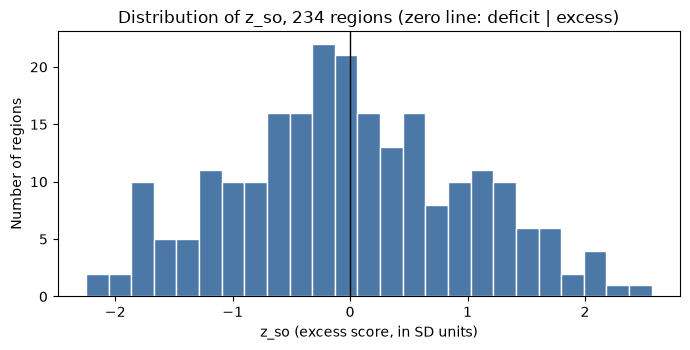

In [38]:
import matplotlib.pyplot as plt

z = model["z_so"]
# z is standardised on exactly these units, so its summary should show a mean of 0 and an SD of 1.
zsum = pd.DataFrame({
    "n": [z.count()], "mean": [z.mean()], "sd (n-1)": [z.std(ddof=1)], "min": [z.min()],
    "p25": [z.quantile(0.25)], "median": [z.median()], "p75": [z.quantile(0.75)], "max": [z.max()],
}, index=["z_so"])
display(zsum.round(3) + 0.0)     # "+ 0.0" turns a displayed -0.0 into 0.0 (the mean is zero by construction)

# The groups come from the zero line, not the median, so the stored label must agree with the sign of z.
assert (z != 0).all(), "a z of exactly 0 would belong to neither group"
assert (model["group_so"] == np.where(z > 0, "excess", "deficit")).all()
print("Groups (zero line):", model["group_so"].value_counts().to_dict())

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(z, bins=25, color="#4C78A8", edgecolor="white")
ax.axvline(0, color="black", lw=1)                         # the line that splits deficit from excess
ax.set_xlabel("z_so (excess score, in SD units)")
ax.set_ylabel("Number of regions")
ax.set_title(f"Distribution of z_so, {len(z)} regions (zero line: deficit | excess)")
plt.tight_layout()
plt.show()

### 2c. Average change by group: raw and within-country, side by side
For each outcome and each group (excess z > 0, deficit z < 0):
- **Raw**: the plain average over all model units in the group (all 234).
- **Within-country**: the average of *(the region's outcome minus the average of its own country)* over the units of the group, using the 22 countries with two or more regions. A positive value means the group sits above its own country's average.

`n` is the number of regions behind each number. The last row of each block is the simple gap, excess minus deficit. These are averages and gaps, not estimates, and carry no p-value or interval.

*You can skip the code; the table below is the result.*

In [39]:
GROUPS = ["excess", "deficit"]
rows = []
for o in OUT:
    block = {}                                     # holds this outcome's two group rows, which the gap row subtracts
    for g in GROUPS:
        raw = model.loc[model["group_so"] == g, o]
        sel = multi["group_so"] == g               # the same group inside the within-country sample
        block[g] = {
            "n (raw)": raw.count(), "raw mean": raw.mean(),
            "n (within)": int(sel.sum()), "countries (within)": multi.loc[sel, "country_code"].nunique(),
            "within-country mean": multi.loc[sel, o + "_wc"].mean(),
        }
        rows.append({"outcome": o, "group": g, **block[g]})
    # The gap row is excess minus deficit. A gap has no single n, so the n columns stay empty.
    rows.append({"outcome": o, "group": "excess minus deficit",
                 "n (raw)": np.nan, "raw mean": block["excess"]["raw mean"] - block["deficit"]["raw mean"],
                 "n (within)": np.nan, "countries (within)": np.nan,
                 "within-country mean": block["excess"]["within-country mean"] - block["deficit"]["within-country mean"]})

group_table = pd.DataFrame(rows).set_index(["outcome", "group"])

# The n's must add up to the two samples: 234 regions raw, 229 regions within countries.
assert group_table.xs("shock", level="outcome").loc[GROUPS, "n (raw)"].sum() == len(model)
assert group_table.xs("shock", level="outcome").loc[GROUPS, "n (within)"].sum() == len(multi)
# Whole-number counts (the empty gap-row cells would otherwise turn them into decimals).
group_table = group_table.astype({"n (raw)": "Int64", "n (within)": "Int64", "countries (within)": "Int64"})
display(group_table.round(3))
# Only countries with regions in both groups give a within-country contrast.
both_groups = int((multi.groupby("country_code")["group_so"].nunique() == 2).sum())
print(f"Countries in the within-country sample that contain both groups: {both_groups} of {multi['country_code'].nunique()}")

n (raw)  raw mean  n (within)  countries (within)  within-country mean
outcome  group                                                                                       
shock    excess                    111    -0.869         108                  22               -0.005
         deficit                   123    -0.941         121                  18                0.004
         excess minus deficit     <NA>     0.072        <NA>                <NA>               -0.009
recovery excess                    111     2.366         108                  22               -0.021
         deficit                   123     2.316         121                  18                0.019
         excess minus deficit     <NA>     0.050        <NA>                <NA>               -0.040
net      excess                    111     1.497         108                  22               -0.026
         deficit                   123     1.376         121                  18                0.023
         excess minus deficit     <NA>     0.122        <NA>                <NA>               -0.049

Countries in the within-country sample that contain both groups: 18 of 22


### 2d. Do the two platforms rank regions alike?
Spearman rank correlation between the Stack Overflow z and the GitHub z, over the units that have both. Rank agreement only. GitHub is not used in any model.

*You can skip the code; the printed line is the result.*

In [40]:
pair = master[["z_so", "z_github"]].dropna()      # only units that have both scores can be compared
N_PAIR = len(pair)
# Spearman compares ranks, so it only asks whether the two platforms order the regions alike.
rho = pair["z_so"].corr(pair["z_github"], method="spearman")
print(f"Spearman rank correlation, z_so vs z_github: {rho:.3f}   (N = {N_PAIR}; Guide: about 0.78, N = 228)")
assert N_PAIR == 228, "expected 228 units with both z-scores"                  # replication check against the Guide
assert abs(rho - 0.78) < 0.03, "expected a Spearman correlation of about 0.78"  # replication check, not a result

Spearman rank correlation, z_so vs z_github: 0.785   (N = 228; Guide: about 0.78, N = 228)


### What this section is and is not
**It is** a plain description of the data before any model: how the outcomes are spread, how z is spread, what the average employment changes of the excess and deficit groups look like, and how closely the two platforms rank the regions.

**It is not** a test and not a result.
- The group averages are averages, not estimates of an effect. No p-value or interval is attached, on purpose. Whether a gap is more than noise is judged only from Section 4 (Steps 10-12), with the models and the bootstrap fixed beforehand.
- Raw and within-country averages answer different questions. Raw compares all excess regions with all deficit regions across Europe, so differences between countries (national policy, lockdown rules, series breaks) can be mixed in. Within-country first subtracts each region's own country average, so it compares regions of the same country. It uses only the 22 countries with two or more regions, and a country whose regions are all in one group has no region of the other group to be compared with. Both are shown side by side.
- The within-country averages are averages of deviations from country means, so the two group averages offset each other (weighted by n). The level of one group alone means little; read the gap between the groups. A gap near zero here is an unadjusted contrast, not evidence of no effect.
- The groups are for describing only. The regression uses the continuous z.
- The Spearman correlation says only how closely the two platforms rank regions. It is not an outcome analysis. GitHub is never used in the regression, and its window (2019-2020) includes the shock year.
- Nothing here changes any fixed decision in Section 0.

**End of Part 2.** Descriptives only; nothing has been tested and no conclusion is drawn.
**Next: Section 3 — main regressions (Step 9), to start only on instruction.**

## 3. Main regressions (Step 9): point estimates only
This is the first time z_so is regressed on the outcomes. The three models below were written to `docs/STATISTICS_LOG.md` ("Step 9 - models fixed before running") **before** anything was run, and they do not change after the results are seen.

**Scope.** Three models fitted by ordinary least squares on the 234 model units, outcomes in percentage points. Only the best-fit numbers (point estimates) are shown. Standard errors, p-values, intervals, the bootstrap, the Holm correction and the 1 pp margin come in Steps 10-12.

### 3a. The three models and how to read beta
```
Shock       : shock    = country_effect + beta*z_so + g1*ln_pop + g2*ln_gdp + error            (H1a)
Recovery A  : recovery = country_effect + beta*z_so + g1*ln_pop + g2*ln_gdp + error            (H1b, PRIMARY)
Recovery B  : recovery = country_effect + beta*z_so + d*shock + g1*ln_pop + g2*ln_gdp + error  (SECONDARY)
```
- **country_effect**: a separate baseline for each country (one 0/1 dummy per country; in the code this is `C(country_code)`). So a region is compared with regions of its own country, which removes anything that affects all regions of a country equally (national rules, lockdown policy, national statistics). A difference that varies between regions of the same country is not removed.
- **z_so** is the continuous excess score (not the excess/deficit groups). **ln_pop** and **ln_gdp** are held constant so the comparison is between regions of similar size and income.
- **beta** is the number the question is about: the change in the employment-rate change, in percentage points, linked to a region having a 1 SD higher z_so than another region of the same country with the same population and income. For the shock a positive beta means a smaller drop; for the recovery a positive beta means a stronger recovery.
- **g1, g2** (and **d**, the shock control in Recovery B) are controls. They are listed only for completeness.
- beta describes an association, not a cause. Here we only compute it; how uncertain it is comes later.

### 3b. The three models as formulas
Each model is written as a formula that reads almost like the sentence in 3a. For example `shock ~ z_so + ln_pop + ln_gdp + C(country_code)` means: explain `shock` by `z_so`, `ln_pop` and `ln_gdp`, with a separate baseline for each country (`C(country_code)`). The call `smf.ols(...).fit()` finds the best-fit numbers by ordinary least squares. We keep only the coefficients here; standard errors and p-values are not used in this step.

`SPECS` lists the same models as (outcome, regressors). The bootstrap in Section 4 uses that form, and a check in Appendix B confirms that it matches the formulas. The **within-R2** is the share of the variation *inside* countries that the regressors explain (the country baselines are not counted).

*You can skip the code; the tables in 3c are the result.*

In [41]:
import statsmodels.formula.api as smf      # lets us write each regression as a formula

# The three models as plain formulas. C(country_code) gives every country its own baseline (the "country effect").
FORMULAS = {
    "Shock":      "shock    ~ z_so + ln_pop + ln_gdp + C(country_code)",             # H1a
    "Recovery A": "recovery ~ z_so + ln_pop + ln_gdp + C(country_code)",             # H1b, primary
    "Recovery B": "recovery ~ z_so + shock + ln_pop + ln_gdp + C(country_code)",     # secondary: also holds the shock constant
}
# The same models as (outcome, regressors): the form the bootstrap in Section 4 needs.
SPECS = {
    "Shock":      ("shock",    ["z_so", "ln_pop", "ln_gdp"]),
    "Recovery A": ("recovery", ["z_so", "ln_pop", "ln_gdp"]),
    "Recovery B": ("recovery", ["z_so", "shock", "ln_pop", "ln_gdp"]),
}
COEF_NAMES = {"z_so": "beta", "ln_pop": "g1", "ln_gdp": "g2", "shock": "d"}   # the names used in the formulas of 3a

# Ordinary least squares on the 234 model regions. Only the coefficients are used in this step.
ols_fits = {name: smf.ols(formula, data=model).fit() for name, formula in FORMULAS.items()}


def within_r2(fit, outcome):
    """Share of the variation inside countries that the regressors explain (the country baselines are not counted)."""
    y_within = model[outcome] - model.groupby("country_code")[outcome].transform("mean")
    return 1.0 - fit.ssr / (y_within ** 2).sum()

### 3c. Fit the three models and show the results
The first table has one row per model: beta (percentage points per 1 SD of z_so), the number of regions, the number of countries with 2 or more regions, the regions effectively used, and the within-R2. The second table has the control coefficients (g1 for ln_pop, g2 for ln_gdp, and d for the shock, which only Recovery B has). The numbers are point estimates; nothing is tested.

*You can skip the code; the tables below are the result.*

In [42]:
# Countries that can contribute are those with 2+ regions; the other five have nothing to be compared with.
contributing = n_per_country[n_per_country >= 2]

rows = []
for name, fit in ols_fits.items():
    outcome = SPECS[name][0]
    rows.append({
        "model": name, "outcome": outcome,
        "beta (pp per 1 SD)": fit.params["z_so"],
        "N regions": int(fit.nobs), "countries (2+ regions)": len(contributing),
        "N effective": int(contributing.sum()), "within-R2": within_r2(fit, outcome),
    })
results3 = pd.DataFrame(rows).set_index("model")
display(results3.round({"beta (pp per 1 SD)": 4, "within-R2": 4}))

# The controls: g1 = ln_pop, g2 = ln_gdp, d = shock (only Recovery B has it; the others stay empty).
controls = pd.DataFrame({
    name: {f"{COEF_NAMES[k]} ({k})": fit.params[k] for k in SPECS[name][1] if k != "z_so"}
    for name, fit in ols_fits.items()
}).T[["g1 (ln_pop)", "g2 (ln_gdp)", "d (shock)"]]
display(controls.round(4))

,outcome,beta (pp per 1 SD),N regions,countries (2+ regions),N effective,within-R2
model,,,,,,
Shock,shock,0.0295,234,22,229,0.0196
Recovery A,recovery,0.0478,234,22,229,0.0247
Recovery B,recovery,0.0664,234,22,229,0.2107


,g1 (ln_pop),g2 (ln_gdp),d (shock)
Shock,-0.0265,-0.6256,NaN
Recovery A,0.2527,0.4725,NaN
Recovery B,0.2360,0.0784,-0.6299


### 3d. Checks
The checks for this step are in Appendix B: the design matrix has full rank, the same coefficients come out by a second route (subtracting country means first), and they do not change when the five single-region countries are left out. The next line runs them and stops the notebook if one fails.

In [43]:
run_checks("step9")

All checks passed (see Appendix B).


### What this section is and is not
**It is** the first regression of the outcomes on z_so, giving plain best-fit numbers (point estimates) from three models fixed beforehand.

**It is not** a result or a test.
- No standard errors, p-values, intervals, bootstrap, Holm correction or 1 pp margin yet. They come in Steps 10-12, and they are needed before anything can be said about whether a number is large or small compared with noise.
- No conclusion about H1a, H1b or H1 is drawn here, and no number is read as support for or against any hypothesis.
- Only these three models. No other sample, control, weighting, outlier rule, GitHub z, income grouping or net change (the 229-region refit in Appendix B1 is a check only). 2021 is not used.
- beta is an association between z_so and the outcome inside countries, not a cause.
- Recovery A is the primary recovery model. Recovery B holds the shock constant and is a secondary check (Guide, decision 14).
- The self-checks confirm the arithmetic (the same answer by different routes). They say nothing about whether the models are right.

**End of Part 3.** Point estimates only; nothing has been tested and no conclusion is drawn.
**Next: Section 4 — wild cluster bootstrap-t, 95% intervals and Holm (Step 10), to start only on instruction.**

## 4. Uncertainty (Step 10): wild cluster bootstrap-t, 95% intervals, Holm
Step 9 gave one best-fit number (beta) per model. This section measures how much that number could move by chance. The method was written to `docs/STATISTICS_LOG.md` ("Step 10 - method fixed before running") **before** the bootstrap was run, and it does not change after the results are seen (any later change would be reported as a deviation, with a reason).

**Scope.** The same three models and sample as Step 9. For each model: beta, a cluster-robust standard error, a bootstrap p-value, a 95% interval, and the Holm-adjusted p-values for H1a and H1b. No reading rule, no 1 pp margin and no verdict here (Steps 11-12).

### 4a. The method in plain words
Regions of one country resemble each other, and only 22 countries have two or more regions, so the usual formulas may be too optimistic. The **wild cluster bootstrap-t** deals with this:

1. **Pretend there is no link.** Refit the model with beta fixed at 0 (the "null"). What is left over for each region (its *leftover*, or residual) is what a model with no z_so link cannot explain.
2. **Replay the data 9,999 times.** In each replay every country flips a coin, +1 or -1. Plus keeps all of that country's leftovers as they are; minus reverses the sign of all of them. All regions of a country move together, so the way regions of one country resemble each other is kept. New outcome = fitted value under "no link" + coin x leftover.
3. **Refit and measure.** In each replay, refit the full model (with beta free) and compute t* = (beta* - beta0) / SE*, where beta0 is the value being tested (0 for the main p-values) and SE* is the cluster-robust standard error (CR1, grouped by country).
4. **Compare.** The observed t is (beta-hat - beta0) / SE from the real data. The p-value is (1 + the number of replays with |t*| at least as large as |observed t|) / (9,999 + 1): how often the replays (where beta = 0 is imposed) produce a t as large as ours, in either direction.
5. **95% interval.** Repeat the whole test for many hypothesised values of beta (beta0, not just 0). The interval is the stretch of beta0 values around beta-hat with p above 0.05, found with a grid and then bisection to 1e-4 pp.
6. **Holm correction.** Because H1a (shock) and H1b (recovery A) are two tests of the same question, their p-values are adjusted so the chance of a false alarm stays controlled: the smaller one is doubled, and the larger one is the larger of itself and the adjusted smaller one (never above 1). Recovery B is secondary and is not adjusted.

*Analogy.* Think of each country's leftovers as one photograph of how that country's regions deviate from the pattern. In each replay we either keep every photograph or turn some of them upside down, whole photographs and never parts of them. Doing this 9,999 times shows how strong a z_so link can look purely by luck. The p-value says how often luck matches or beats what we observed.

### 4b. The bootstrap sample and the coin flips
The bootstrap uses the **229 regions in the 22 countries with two or more regions**. The five single-region countries (CY, EE, LU, LV, MT) are left out because, once a country has its own baseline, they have no leftover to flip (their residual is exactly zero). A check in Appendix B confirms that leaving them out does not change beta.

The coin flips (the weights) are drawn **once**, with seed 42, countries in alphabetical order, and the same flips are reused for every model and for every hypothesised beta0.

*You can skip the code; the printed line is the result.*

In [44]:
# Only the 229 regions in countries with 2+ regions: CY, EE, LU, LV and MT have nothing left to flip.
boot_data = model[model["country_code"].map(n_per_country) >= 2].copy()
# Group the regions by country and draw the coin flips once (seed 42): every model and every test reuses the same flips.
sample = make_bootstrap_sample(boot_data, seed=SEED, n_boot=N_BOOT)
print(f"Bootstrap sample: {sample.n_regions} regions, {sample.n_clusters} clusters, {N_BOOT:,} draws, seed {SEED}")

Bootstrap sample: 229 regions, 22 clusters, 9,999 draws, seed 42


### 4c. What the functions do
The bootstrap code is in the helper-code block near the top (it has to run before this section), and Appendix A explains it step by step. In short:
- `make_bootstrap_sample` groups the 229 regions by country and draws the coin flips once.
- `prep_model` fits one model on the real data and keeps what every replay will reuse (a `ModelFit`: the observed beta, its CR1 standard error, and the demeaned data).
- `boot_p(fit, beta0)` runs the whole wild bootstrap-t for the hypothesis beta = beta0 and returns the p-value (it can also return all the t* values).
- `ci_endpoints(fit)` finds the 95% interval by test inversion: a grid of 121 values of beta0 around beta-hat, then bisection.
- `holm_two` applies the Holm correction to the two primary tests.

### 4d. Run the bootstrap for the three models
For each model the next cell computes the observed beta and its cluster-robust SE, the bootstrap p-value for beta = 0, and the 95% interval. The first table has one row per model. The second table has the Holm-adjusted p-values for H1a (Shock) and H1b (Recovery A) only. These are the numbers Steps 11-12 will use. Nothing is read or judged here. The table shows two counts: "N regions (Step 9)" is the 234 regions of the model, and "N regions (bootstrap sample)" is the 229 regions in the countries with two or more regions, which is what the bootstrap uses.

*You can skip the code; the tables below are the result.*

In [45]:
# Get each model ready once on the real data (country baselines removed).
boot_fits = {name: prep_model(sample, name, *SPECS[name]) for name in SPECS}

BOOT = {}
for name, fit in boot_fits.items():
    # The p-value tests "beta = 0"; the 95% interval is the set of beta0 values that the same test does not reject.
    p, t_star, t_obs = boot_p(fit, 0.0, keep_t=True)
    lo, hi = ci_endpoints(fit)
    BOOT[name] = {"p": p, "t_star": t_star, "t_obs": t_obs, "lo": lo, "hi": hi}

rows = []
for name, fit in boot_fits.items():
    b = BOOT[name]
    rows.append({
        "model": name, "outcome": fit.outcome,
        "beta (pp per 1 SD)": fit.beta_hat, "SE (CR1)": fit.se, "bootstrap p": b["p"],
        "95% interval low": b["lo"], "95% interval high": b["hi"],
        "N regions (Step 9)": len(model), "N regions (bootstrap sample)": sample.n_regions, "clusters": sample.n_clusters,
    })
results4 = pd.DataFrame(rows).set_index("model")
display(results4.round({"beta (pp per 1 SD)": 4, "SE (CR1)": 4, "bootstrap p": 4, "95% interval low": 4, "95% interval high": 4}))

# Holm across H1a (Shock) and H1b (Recovery A) only. Recovery B is secondary and is not adjusted.
holm = holm_two(BOOT["Shock"]["p"], BOOT["Recovery A"]["p"])
holm_table = pd.DataFrame({
    "test": ["H1a (Shock)", "H1b (Recovery A)"],
    "bootstrap p": [BOOT["Shock"]["p"], BOOT["Recovery A"]["p"]],
    "Holm-adjusted p": [holm["H1a"], holm["H1b"]],
}).set_index("test")
display(holm_table.round(4))

,outcome,beta (pp per 1 SD),SE (CR1),bootstrap p,95% interval low,95% interval high,N regions (Step 9),N regions (bootstrap sample),clusters
model,,,,,,,,,
Shock,shock,0.0295,0.0999,0.7680,-0.1565,0.2816,234,229,22
Recovery A,recovery,0.0478,0.1620,0.7669,-0.2719,0.4472,234,229,22
Recovery B,recovery,0.0664,0.1582,0.6652,-0.2391,0.4615,234,229,22


,bootstrap p,Holm-adjusted p
test,,
H1a (Shock),0.7680,1.0
H1b (Recovery A),0.7669,1.0


### 4e. What the bootstrap t* values look like
One panel per model. The histogram shows the 9,999 t* values from the replays in which beta = 0 is imposed, which is how large t can look by chance alone. The solid red line is the observed t; the dashed line is its mirror image, because the test counts both tails.

*You can skip the code; the figure below is the result.*

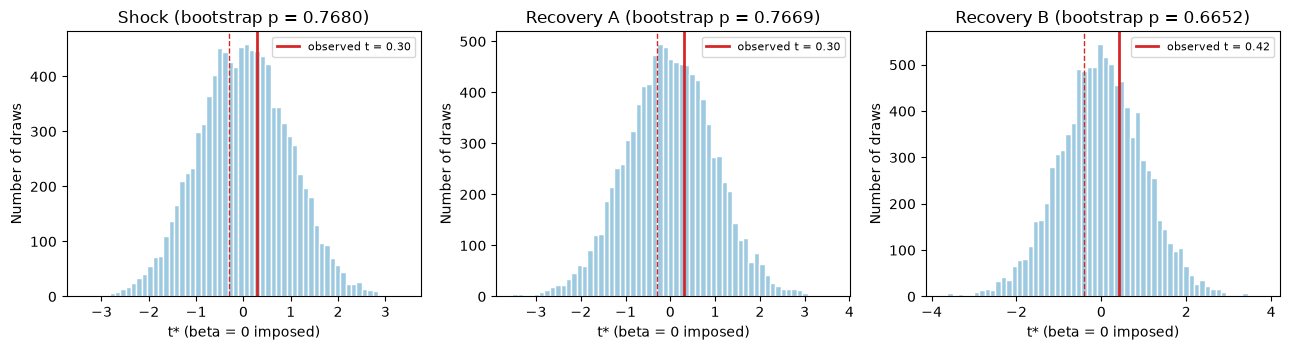

In [46]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (name, b) in zip(axes, BOOT.items()):
    ax.hist(b["t_star"], bins=60, color="#9ecae1", edgecolor="white")
    ax.axvline(b["t_obs"], color="#d62728", lw=2, label=f"observed t = {b['t_obs']:.2f}")
    ax.axvline(-b["t_obs"], color="#d62728", lw=1, ls="--")        # the test is two-sided, so the mirror image counts too
    ax.set_title(f"{name} (bootstrap p = {b['p']:.4f})")
    ax.set_xlabel("t* (beta = 0 imposed)")
    ax.set_ylabel("Number of draws")
    ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

### 4f. Checks
The checks for this step are in Appendix B: our standard error equals the statsmodels one, the same seed gives the same p-values, the t* values are centred and symmetric, the p-value at each interval end is just above 0.05, and the restricted fit reproduces the unrestricted fit when beta0 equals beta-hat. The next line runs them and stops the notebook if one fails.

In [47]:
run_checks("step10")

All checks passed (see Appendix B).


### What this section is and is not
**It is** the uncertainty around the three Step 9 numbers: a cluster-robust standard error, a wild cluster bootstrap-t p-value for beta = 0, a 95% interval, and the Holm-adjusted p-values for H1a and H1b, all by the method fixed beforehand.

**It is not** a verdict.
- No reading rule, no 1 pp margin, no "supported", "not supported" or "no difference" statement here. The smallest detectable effect (Step 11) and the fixed reading rule (Step 12) come next, and they are needed to read these numbers.
- beta is an association between z_so and the outcome inside countries, not a cause. A p-value says how often the replays match the observed t; it does not measure the size or importance of beta.
- Only the bootstrap p-values are reported. No asymptotic (t or normal) p-values are shown anywhere.
- Recovery B is secondary: its p-value and interval are reported without the Holm adjustment.
- The self-checks confirm the arithmetic and the procedure. They say nothing about whether the models are right.

**End of Part 4.** Uncertainty measured by the fixed method; no reading rule applied and no conclusion drawn.
**Next: Section 5 — smallest detectable effect against the 1 pp margin (Step 11), to start only on instruction.**

## 5. Smallest detectable effect (Step 11)
Step 10 measured the uncertainty around each beta. This section asks a different question: **how small an effect could these data have picked up at all?** If that smallest effect is large, small effects would have been missed.

**Scope.** Only Shock (H1a) and Recovery A (H1b, primary). Recovery B is not part of Step 11. The method was written to `docs/STATISTICS_LOG.md` ("Step 11 - method fixed before running") **before** anything here was computed, and it does not change after the results are seen (any later change would be reported as a deviation, with a reason). No reading rule and no verdict about H1 here; that is Step 12.

### 5a. What the smallest detectable effect is
**In plain words.** The smallest detectable effect (SDE) is the smallest true beta that a test at the 5% level would pick up 8 times out of 10 (80% power), given how noisy these data are. *Analogy:* a microphone in a noisy room. A whisper at the level of the room noise is mostly missed. The SDE is the quietest voice that would be clearly picked up (pass the 5% test) 8 times out of 10; anything much quieter is often missed. If the SDE is larger than the margin m, a real signal of size m could be missed.

**Formula.**
```
SDE = factor x SE(beta)          factor = t(0.975, 21 df) + t(0.80, 21 df)
```
Both terms are in SE units (multiplying by SE converts them to percentage points). The first term is the distance from 0 to the two-sided 5% cut-off. The second term adds the extra distance needed so that, if the true effect equals the SDE, the 5% test rejects about 8 times in 10 (80% power).

**Which factor.** The Guide gives 2.8 (a normal approximation) and says it is nearer 2.9 with about 22 clusters, and that we must state which one we use. **We use the t-based factor with 21 degrees of freedom (22 clusters minus 1) as the headline.** The Guide's 2.8 is shown in a side column.

**Inputs.** beta and SE (the cluster-robust CR1 standard error) are the values stored in Step 10, not re-estimated. The margin m (1 pp per 1 SD of z_so) is the constant fixed in Section 0.

**Comparison.** If the SDE is smaller than m, effects of size m could be detected. If it is larger, effects of size m cannot be ruled out. This is a statement about how sensitive the data are. It is not a verdict about H1.

**Limitation (stated).** The SDE treats the estimated SE as if it were the true SE. With only about 22 clusters, the SE itself is uncertain, so the SDE is approximate.

### 5b. The factor and the results table
The next cell works out the two factors (the t-based headline and, for reference, the normal approximation), then builds one table with a row per model: beta, SE, the SDE with the headline factor, the SDE with the Guide's 2.8, the margin m, the margin expressed in SE units (m divided by SE), and the plain statement comparing the headline SDE with m.

*You can skip the code; the table below is the result.*

In [48]:
from scipy import stats

POWER = 0.80                   # 80% power (Guide, Step 11)
DF = sample.n_clusters - 1     # degrees of freedom: 22 clusters minus 1 = 21
# Factor = distance from 0 to the two-sided 5% cut-off + the extra distance that gives 80% power
FACTOR_T = stats.t.ppf(1 - ALPHA / 2, DF) + stats.t.ppf(POWER, DF)
FACTOR_NORMAL = stats.norm.ppf(1 - ALPHA / 2) + stats.norm.ppf(POWER)          # normal approximation, for reference only
print(f"t-based factor (headline, {DF} df): {FACTOR_T:.4f}")
print(f"Guide factor (Section 0, SD_FACTOR):  {SD_FACTOR}")
print(f"Normal approximation, for reference: {FACTOR_NORMAL:.4f}")

SDE_MODELS = ["Shock", "Recovery A"]            # H1a and H1b (primary); Recovery B is not part of Step 11
rows = []
for name in SDE_MODELS:
    beta, se = boot_fits[name].beta_hat, boot_fits[name].se      # the stored Step 10 values, not re-estimated
    sde_t = FACTOR_T * se
    sde_guide = SD_FACTOR * se                                    # the same with the Guide's 2.8
    if sde_t < MARGIN_PP:                                         # the margin comes from Section 0
        statement = "smaller than the margin: effects of size m could be detected"
    else:
        statement = "larger than the margin: effects of size m cannot be ruled out"
    rows.append({
        "model": name, "beta (pp per 1 SD)": beta, "SE (CR1)": se,
        "SDE (t-based, headline)": sde_t, f"SDE (Guide factor {SD_FACTOR})": sde_guide,
        "margin m (pp)": MARGIN_PP, "margin in SE units (m / SE)": MARGIN_PP / se,
        "headline SDE vs margin": statement,
    })
results5 = pd.DataFrame(rows).set_index("model")
with pd.option_context("display.max_colwidth", None, "display.width", 220):    # show the full statement text, not "..."
    display(results5.round({"beta (pp per 1 SD)": 4, "SE (CR1)": 4, "SDE (t-based, headline)": 4,
                            f"SDE (Guide factor {SD_FACTOR})": 4, "margin in SE units (m / SE)": 2}))

t-based factor (headline, 21 df): 2.9387
Guide factor (Section 0, SD_FACTOR):  2.8
Normal approximation, for reference: 2.8016


,beta (pp per 1 SD),SE (CR1),"SDE (t-based, headline)",SDE (Guide factor 2.8),margin m (pp),margin in SE units (m / SE),headline SDE vs margin
model,,,,,,,
Shock,0.0295,0.0999,0.2936,0.2798,1.0,10.01,smaller than the margin: effects of size m could be detected
Recovery A,0.0478,0.1620,0.4761,0.4536,1.0,6.17,smaller than the margin: effects of size m could be detected


### 5c. A picture of the three sizes
For each model: the size of the observed |beta|, the smallest detectable effect with the Guide's 2.8, the smallest detectable effect with the headline t-based factor, and the margin m (dashed line). The observed |beta| is drawn only for scale; nothing is decided by comparing it with the SDE.

*You can skip the code; the figure below is the result.*

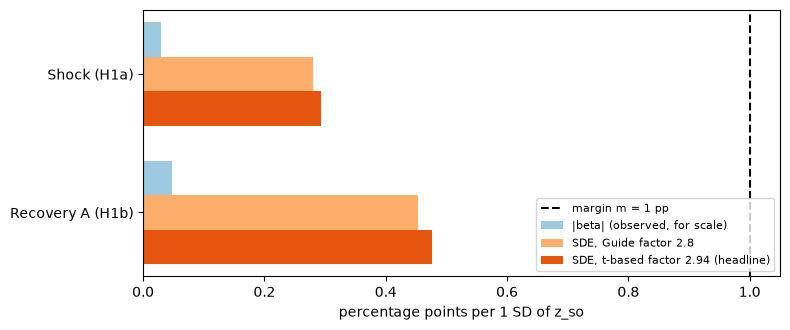

In [49]:
import matplotlib.pyplot as plt

assert list(results5.index) == SDE_MODELS            # the labels below are typed by hand, so they must match the table rows
labels = ["Shock (H1a)", "Recovery A (H1b)"]
guide_col = f"SDE (Guide factor {SD_FACTOR})"
abs_beta = results5["beta (pp per 1 SD)"].abs().to_numpy()       # the observed |beta|, drawn only for scale
sde_guide = results5[guide_col].to_numpy()
sde_head = results5["SDE (t-based, headline)"].to_numpy()

y = np.arange(len(SDE_MODELS))
h = 0.25
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(y - h, abs_beta, h, color="#9ecae1", label="|beta| (observed, for scale)")
ax.barh(y, sde_guide, h, color="#fdae6b", label=f"SDE, Guide factor {SD_FACTOR}")
ax.barh(y + h, sde_head, h, color="#e6550d", label=f"SDE, t-based factor {FACTOR_T:.2f} (headline)")
ax.axvline(MARGIN_PP, color="black", ls="--", label=f"margin m = {MARGIN_PP:g} pp")   # the margin comes from Section 0
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.invert_yaxis()                                               # first model at the top
ax.set_xlabel("percentage points per 1 SD of z_so")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

### 5d. Checks
The checks for this step are in Appendix B: the SE and beta equal the Step 10 table, each SDE equals factor x SE, the t-based factor lies between 2.8 and 3.0 and is built from 21 degrees of freedom, and the margin is the Section 0 constant. The next line runs them and stops the notebook if one fails.

In [50]:
run_checks("step11")

All checks passed (see Appendix B).


### What this section is and is not
**It is** a measure of how sensitive the data are: the smallest effect the two primary tests (Shock and Recovery A) could have picked up with 80% power, set against the margin m.

**It is not** a test and not a verdict.
- It does not say whether any real effect exists. The SDE is computed from the SE alone, not from the observed beta (beta and |beta| appear in the table and the chart only for scale).
- No reading rule and no statement about H1, H1a or H1b here. The fixed reading rule is applied in Step 12.
- Recovery B is not part of Step 11.
- The SDE treats the estimated SE as the true SE. With about 22 clusters the SE itself is uncertain, so the SDE is approximate. The headline factor (t-based, 21 degrees of freedom) is somewhat larger than the Guide's 2.8; both are shown.
- The self-checks confirm the arithmetic. They say nothing about whether the models are right.

**End of Part 5.** Sensitivity of the data measured; no reading rule applied and no conclusion drawn.
**Next: Section 6 — reading the answer with the fixed rule (Step 12), to start only on instruction.**

## 6. Reading the answer (Step 12)
This is the last analysis step. It takes the stored results of Sections 4 and 5 and applies the reading rule that the Guide fixed in advance (Section 7). The way the rule's parts combine was written to `docs/STATISTICS_LOG.md` ("Step 12 - reading rule fixed before applying") **before** the rule was applied. The rule is applied mechanically: no judgement, and no change after the result is seen (any later change would be reported as a deviation, with a reason).

**Scope.** No new estimate, test or specification. No result number is typed in this section (the only typed numbers are the made-up ones in the tests, listed in Appendix B). Every result number comes from the stored results of Sections 4 and 5, and every sentence that contains a number is built from those stored variables.

### 6a. The rule in plain words
**Inputs** (stored, for H1a = shock and H1b = Recovery A): beta, the bootstrap p-value, the 95% interval and the smallest detectable effect (SDE); the margin m (Section 0); the test level alpha (Section 0).

**Significant** always means significant *after the Holm correction*: the smaller of the two p-values must be below 0.025, and only then is the larger one compared with 0.05. A **positive** estimate means a smaller drop (H1a) or a stronger recovery (H1b).

**Decision list, in this order:**
1. **If at least one of H1a and H1b is significant:**
   - if the two estimates have opposite signs: **Mixed result** (both are reported);
   - otherwise, if a significant estimate is positive: **H1 supported**;
   - otherwise, if a significant estimate is negative: **Evidence against H1 (excess regions did worse)**.
2. **Otherwise**, if both 95% intervals lie strictly inside the band from -m to +m **and** both SDEs are smaller than m: **No meaningful difference**.
3. **Otherwise: Inconclusive**, and we say so plainly.

**How the parts were fixed.** The Guide's reading rule (Section 7) was fixed on 13 November 2026, before any result was seen. Two details of how its parts combine, the SDE condition inside "No meaningful difference" (from Step 11) and the order of the checks inside item 1, were fixed in the log after the results of Sections 4 and 5 were stored, but before the rule was applied.

**Recovery B is a check only.** It never changes the verdict. We report whether it points the same way as Recovery A (the sign) and whether its interval lies inside the band from -m to +m.

### 6b. The function that applies the rule
`read_answer(...)` is the rule written as code. The cells below define the five answers and the function, and then run its tests on made-up inputs (they are listed in Appendix B): every branch of the rule must return the label written next to it, including the case where a significant result inside the margin still counts as "supported". The notebook stops if one test fails, so the rule is only used on the real results after it has passed.

*You can skip the code; 6a explains the rule in plain words and the next cells use the function.*

The five possible answers, written once so that the whole notebook uses the same wording.

In [51]:
# The five possible answers, with the exact wording used in the notebook.
LABELS = {
    "supported": "H1 supported",
    "against": "Evidence against H1 (excess regions did worse)",
    "mixed": "Mixed result",
    "nmd": "No meaningful difference",
    "inconclusive": "Inconclusive",
}

The reading rule as code: it takes the stored results and returns one of the five answers.

In [52]:
def read_answer(beta_a, p_a, ci_a, sde_a, beta_b, p_b, ci_b, sde_b, m, alpha):
    """Apply the fixed reading rule (Guide Section 7) mechanically. a = H1a (shock), b = H1b (Recovery A)."""
    # Holm: the smaller p must be below alpha/2, and only then is the larger p compared with alpha.
    a_is_smaller = p_a <= p_b                              # if the p-values tie, H1a counts as the smaller
    p_min, p_max = (p_a, p_b) if a_is_smaller else (p_b, p_a)
    sig_min = p_min < alpha / 2
    sig_max = sig_min and p_max < alpha
    sig_a, sig_b = (sig_min, sig_max) if a_is_smaller else (sig_max, sig_min)
    # Positive = smaller drop (H1a) or stronger recovery (H1b); an estimate of exactly 0 is neither.
    pos_a, neg_a, pos_b, neg_b = beta_a > 0, beta_a < 0, beta_b > 0, beta_b < 0
    opposite = (pos_a and neg_b) or (neg_a and pos_b)
    sig_pos = (sig_a and pos_a) or (sig_b and pos_b)
    sig_neg = (sig_a and neg_a) or (sig_b and neg_b)
    # Ingredients of "no meaningful difference": both intervals strictly inside (-m, +m) and both SDEs smaller than m.
    inside_a = (-m < ci_a[0]) and (ci_a[1] < m)
    inside_b = (-m < ci_b[0]) and (ci_b[1] < m)
    sde_ok_a, sde_ok_b = sde_a < m, sde_b < m
    if sig_a or sig_b:                                      # the first item of the list wins over the second
        if opposite:
            key = "mixed"
        elif sig_pos:
            key = "supported"
        elif sig_neg:
            key = "against"
        else:
            key = "inconclusive"                            # safety net only: a significant estimate of exactly 0 cannot occur
    elif inside_a and inside_b and sde_ok_a and sde_ok_b:
        key = "nmd"
    else:
        key = "inconclusive"
    return {"key": key, "label": LABELS[key], "sig_a": sig_a, "sig_b": sig_b, "opposite": opposite,
            "inside_a": inside_a, "inside_b": inside_b, "sde_ok_a": sde_ok_a, "sde_ok_b": sde_ok_b}

Run the test cases of the rule (they are listed in Appendix B) before the rule is applied to the real results; the notebook stops if one fails.

In [53]:
# The made-up test cases (listed in Appendix B) must pass before the rule is used on the real results.
_ = run_rule_tests()

### 6c. The results side by side
One table with the three models: Shock (H1a, primary), Recovery A (H1b, primary) and Recovery B (a check only). All numbers are read from the stored results of Sections 4 and 5. The Holm-adjusted p-value and the SDE exist for the two primary tests only. "Regions" shows the regions in the model and the regions used by the bootstrap.

*You can skip the code; the table below is the result.*

In [54]:
# The inputs come from the stored Step 10 and Step 11 results; nothing is retyped.
ROLE = {"Shock": "H1a, primary", "Recovery A": "H1b, primary", "Recovery B": "check only"}
rows = []
for name in ["Shock", "Recovery A", "Recovery B"]:
    primary = name in ("Shock", "Recovery A")
    rows.append({
        "model": name, "role": ROLE[name],
        "beta (pp per 1 SD)": boot_fits[name].beta_hat, "SE (CR1)": boot_fits[name].se,
        "bootstrap p": BOOT[name]["p"],
        "95% low": BOOT[name]["lo"], "95% high": BOOT[name]["hi"],
        "Holm-adjusted p": holm["H1a" if name == "Shock" else "H1b"] if primary else np.nan,       # defined for the primary tests only
        "regions (model / bootstrap)": f"{len(model)} / {sample.n_regions}", "clusters": sample.n_clusters,
        "SDE (headline)": results5.loc[name, "SDE (t-based, headline)"] if primary else np.nan,   # defined for the primary tests only
    })
final_table = pd.DataFrame(rows).set_index("model")
with pd.option_context("display.width", 220, "display.max_columns", 30):
    display(final_table.round({"beta (pp per 1 SD)": 4, "SE (CR1)": 4, "bootstrap p": 4, "95% low": 4, "95% high": 4,
                               "Holm-adjusted p": 4, "SDE (headline)": 4}))

# What read_answer needs, for the two primary tests only (a = H1a, b = H1b).
inp = {}
for key, name in (("a", "Shock"), ("b", "Recovery A")):
    inp[key] = {"beta": boot_fits[name].beta_hat, "p": BOOT[name]["p"], "ci": (BOOT[name]["lo"], BOOT[name]["hi"]),
                "sde": results5.loc[name, "SDE (t-based, headline)"]}
answer = read_answer(inp["a"]["beta"], inp["a"]["p"], inp["a"]["ci"], inp["a"]["sde"],
                     inp["b"]["beta"], inp["b"]["p"], inp["b"]["ci"], inp["b"]["sde"], MARGIN_PP, ALPHA)

,role,beta (pp per 1 SD),SE (CR1),bootstrap p,95% low,95% high,Holm-adjusted p,regions (model / bootstrap),clusters,SDE (headline)
model,,,,,,,,,,
Shock,"H1a, primary",0.0295,0.0999,0.7680,-0.1565,0.2816,1.0,234 / 229,22,0.2936
Recovery A,"H1b, primary",0.0478,0.1620,0.7669,-0.2719,0.4472,1.0,234 / 229,22,0.4761
Recovery B,check only,0.0664,0.1582,0.6652,-0.2391,0.4615,NaN,234 / 229,22,NaN


### 6d. The coefficient plot
Each dot is beta, the horizontal bar is its 95% interval, in percentage points per 1 SD of z. The grey band is the margin m on each side of zero, and the black line marks zero. Shock and Recovery A are the primary tests; Recovery B (open dot) is the check.

*You can skip the code; the figure below is the result.*

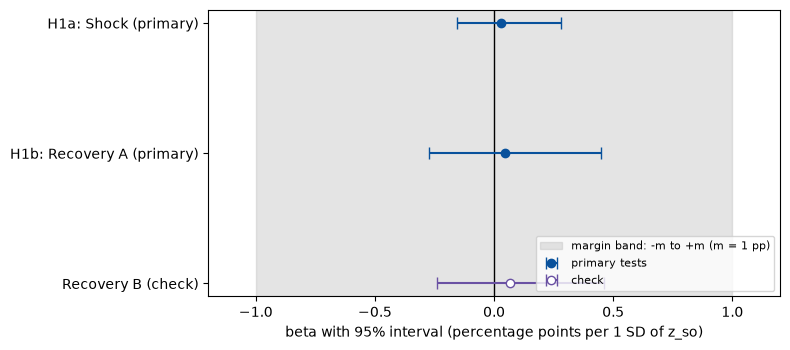

In [55]:
import matplotlib.pyplot as plt

names = ["Shock", "Recovery A", "Recovery B"]
est = np.array([boot_fits[n].beta_hat for n in names])
lo = np.array([BOOT[n]["lo"] for n in names])
hi = np.array([BOOT[n]["hi"] for n in names])
xerr = np.vstack([est - lo, hi - est])                               # distances from beta to each end, as errorbar wants them
ylab = ["H1a: Shock (primary)", "H1b: Recovery A (primary)", "Recovery B (check)"]
ypos = np.arange(len(names))
assert names == list(boot_fits) and ylab[0].startswith("H1a") and ylab[1].startswith("H1b") and ylab[2].startswith("Recovery B")   # the typed labels must match the model order

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axvspan(-MARGIN_PP, MARGIN_PP, color="#bdbdbd", alpha=0.4, label=f"margin band: -m to +m (m = {MARGIN_PP:g} pp)")
ax.axvline(0, color="black", lw=1)
ax.errorbar(est[:2], ypos[:2], xerr=xerr[:, :2], fmt="o", color="#08519c", capsize=4, label="primary tests")
ax.errorbar(est[2:], ypos[2:], xerr=xerr[:, 2:], fmt="o", color="#6a51a3", mfc="white", capsize=4, label="check")
ax.set_yticks(ypos)
ax.set_yticklabels(ylab)
ax.invert_yaxis()                                                    # first model at the top
ax.set_xlim(min(-1.2 * MARGIN_PP, lo.min() * 1.1), max(1.2 * MARGIN_PP, hi.max() * 1.1))
ax.set_xlabel("beta with 95% interval (percentage points per 1 SD of z_so)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()
# Read back what was actually drawn (the dots and the ends of the bars), so Appendix B can check the figure itself.
PLOT_EST = np.concatenate([cont.lines[0].get_xdata() for cont in ax.containers])
segments = [seg for cont in ax.containers for seg in cont.lines[2][0].get_segments()]
PLOT_LO = np.array([seg[:, 0].min() for seg in segments])
PLOT_HI = np.array([seg[:, 0].max() for seg in segments])

### 6e. The verdict and what it means
The next cells print the verdict from `read_answer` on the real, stored results as one sentence, and then build and print an interpretation paragraph. Every number in both is inserted from the stored variables. The wording is fixed: results are *associated with* excess capacity, never *caused* by it; the margin was fixed in advance; and the result concerns Stack Overflow activity in 2019 as a proxy for programming capacity.

*You can skip the code; the sentence and the paragraph below are the result.*

In [56]:
import textwrap

m = MARGIN_PP
a, b = inp["a"], inp["b"]
label = answer["label"]

# The verdict as one sentence; every number is inserted from the stored variables.
VERDICT = (f"Under the fixed reading rule the answer is: {label} "
           f"(shock: beta = {a['beta']:.4f} pp per 1 SD, 95% interval {a['ci'][0]:.4f} to {a['ci'][1]:.4f}, bootstrap p = {a['p']:.4f}; "
           f"recovery A: beta = {b['beta']:.4f} pp per 1 SD, 95% interval {b['ci'][0]:.4f} to {b['ci'][1]:.4f}, bootstrap p = {b['p']:.4f}; "
           f"margin m = {m:g} pp).")
print(VERDICT)
print()

Under the fixed reading rule the answer is: No meaningful difference (shock: beta = 0.0295 pp per 1 SD, 95% interval -0.1565 to 0.2816, bootstrap p = 0.7680; recovery A: beta = 0.0478 pp per 1 SD, 95% interval -0.2719 to 0.4472, bootstrap p = 0.7669; margin m = 1 pp).



Write the opening of the interpretation paragraph: what the result is about, and the numbers for the shock and for the recovery.

In [57]:
# The interpretation paragraph, also built from the stored variables.
intro = ("This result is about Stack Overflow activity in 2019 used as a proxy for programming capacity. Regions with excess capacity "
         "(more active users than their population and income predict) are compared with regions of the same country, and what is found "
         "is an association, not a cause. "
         f"The margin of {m:g} pp per 1 SD of z was fixed in advance, before any result was seen.")
h1a = (f"For the shock (H1a), 1 SD more excess capacity is associated with a difference of {a['beta']:.4f} pp in the 2019-to-2020 "
       f"employment-rate change (a positive number means a smaller drop): 95% interval {a['ci'][0]:.4f} to {a['ci'][1]:.4f}, "
       f"bootstrap p = {a['p']:.4f}, Holm-adjusted p = {holm['H1a']:.4f}.")
h1b = (f"For the recovery (H1b, Recovery A), it is associated with a difference of {b['beta']:.4f} pp in the 2020-to-2022 "
       f"change (a positive number means a stronger recovery): 95% interval {b['ci'][0]:.4f} to {b['ci'][1]:.4f}, "
       f"bootstrap p = {b['p']:.4f}, Holm-adjusted p = {holm['H1b']:.4f}.")

Add the sentence that depends on the verdict: which of the five answers the rule gave, and why.

In [58]:
if answer["key"] == "supported":
    tail = ("Under the fixed rule this is reported as H1 supported: at least one of the two tests is significant after the Holm "
            "correction with a positive estimate, and no significant estimate is negative. This is an association, not a cause.")
elif answer["key"] == "against":
    tail = ("Under the fixed rule this is reported as evidence against H1: a significant estimate is negative, which means excess "
            "regions did worse, and no significant estimate is positive. This is an association, not a cause.")
elif answer["key"] == "mixed":
    tail = ("Under the fixed rule this is reported as a mixed result: the two estimates have opposite signs and at least one is "
            "significant after the Holm correction. Both results are reported and no single direction is claimed.")
elif answer["key"] == "nmd":
    tail = (f"Neither test is significant after the Holm correction, both 95% intervals lie strictly inside -{m:g} to +{m:g} pp, and the "
            f"smallest detectable effects ({a['sde']:.4f} pp for the shock and {b['sde']:.4f} pp for recovery A) are smaller than the margin. "
            "Under the fixed rule this is reported as no meaningful difference of the size of the margin. It does not show that "
            "excess capacity has no relationship with employment of any size; it says that the 95% intervals do not reach the margin.")
else:
    reasons = []                                         # an Inconclusive answer must say why
    if not (answer["sig_a"] or answer["sig_b"]):
        reasons.append("neither test is significant after the Holm correction")
    if not answer["inside_a"]:
        reasons.append(f"the shock interval is not strictly inside -{m:g} to +{m:g} pp")
    if not answer["inside_b"]:
        reasons.append(f"the recovery A interval is not strictly inside -{m:g} to +{m:g} pp")
    if not answer["sde_ok_a"]:
        reasons.append(f"the smallest detectable effect for the shock ({a['sde']:.4f} pp) is not smaller than the margin")
    if not answer["sde_ok_b"]:
        reasons.append(f"the smallest detectable effect for recovery A ({b['sde']:.4f} pp) is not smaller than the margin")
    assert reasons, "an Inconclusive answer must have at least one reason"
    tail = "Under the fixed rule this is reported as inconclusive, because " + "; ".join(reasons) + ". We say so plainly."

Add the Recovery B check (it never changes the verdict) and print the whole paragraph.

In [59]:
# Recovery B is a check only: it is reported next to the verdict and never changes it.
pb = {"beta": boot_fits["Recovery B"].beta_hat, "ci": (BOOT["Recovery B"]["lo"], BOOT["Recovery B"]["hi"]), "p": BOOT["Recovery B"]["p"]}
same_sign = np.sign(pb["beta"]) == np.sign(b["beta"])
b_inside = (-m < pb["ci"][0]) and (pb["ci"][1] < m)
check_b = (f"Check, Recovery B (not used for the verdict): beta = {pb['beta']:.4f} pp, 95% interval {pb['ci'][0]:.4f} to {pb['ci'][1]:.4f}, "
           f"bootstrap p = {pb['p']:.4f}. Its estimate has the {'same' if same_sign else 'opposite'} sign as Recovery A, and its interval "
           f"{'lies' if b_inside else 'does not lie'} strictly inside -{m:g} to +{m:g} pp.")

INTERPRETATION = " ".join([intro, h1a, h1b, tail, check_b])
print(textwrap.fill(INTERPRETATION, width=120))

This result is about Stack Overflow activity in 2019 used as a proxy for programming capacity. Regions with excess
capacity (more active users than their population and income predict) are compared with regions of the same country, and
what is found is an association, not a cause. The margin of 1 pp per 1 SD of z was fixed in advance, before any result
was seen. For the shock (H1a), 1 SD more excess capacity is associated with a difference of 0.0295 pp in the
2019-to-2020 employment-rate change (a positive number means a smaller drop): 95% interval -0.1565 to 0.2816, bootstrap
p = 0.7680, Holm-adjusted p = 1.0000. For the recovery (H1b, Recovery A), it is associated with a difference of 0.0478
pp in the 2020-to-2022 change (a positive number means a stronger recovery): 95% interval -0.2719 to 0.4472, bootstrap p
= 0.7669, Holm-adjusted p = 1.0000. Neither test is significant after the Holm correction, both 95% intervals lie
strictly inside -1 to +1 pp, and the smallest detectable effec

### 6f. Checks
The checks for this step are in Appendix B: the tests of `read_answer` on made-up inputs, the rule inputs equal the Section 4 and 5 tables, the verdict equals a second, separately written application of the rule, and the plot was drawn from the stored intervals. The next line runs them and stops the notebook if one fails.

In [60]:
run_checks("step12")

All checks passed (see Appendix B).


### 6g. Limitations to state with this result
**Copied from the Guide (Section 9, "Short version for the paper"), verbatim:**

> Our measure of programming capacity is based on Stack Overflow activity in 2019, placed in regions by the city on user profiles (about 61% of EU-located users), and it may not represent all programmers. Excess capacity is defined relative to what population and income predict and is identified mainly within countries, so the analysis rests on about 22 countries and the intervals are wide. Employment rates do not capture hours worked, and series breaks affect part of the sample. We therefore report an association, not a causal effect, and we state a null result only if the whole interval lies within one percentage point.

**Pointers to the Guide's numbered limitations** (Section 9, the Limitation column, copied from the Guide):

- **A. Measuring programming capacity** (Guide limitations 1-5)
  - 1. Stack Overflow is a proxy. It counts active platform users, not all programmers.
  - 2. Users are placed by the city written in their profile, as of October 2026. About 61% of EU-located users could be placed.
  - 3. Placement errors in the location lookup: US state codes (LA, DE, MT) labelled as countries; at least 44 locations with US place names (for example "Potsdam, NY"), about 57 users, placed in EU cities.
  - 4. Deleted accounts: a user counts as active in a year if they posted, even if the account was deleted later.
  - 5. Zero and very low counts: 6 units have zero users (FI20, FRY1 to FRY5); counting those, 14 units have 5 or fewer, so 8 low-count units stay in the model.
- **B. Building the excess score** (Guide limitations 6-9)
  - 6. Excess depends on a two-variable expected-count model (population and income).
  - 7. z is estimated, not observed (a generated regressor).
  - 8. Most variation in z is between countries (about 45%), and 5 countries have one region only.
  - 9. Excess may partly reflect urban status, a capital region or sector structure.
- **C. The outcome** (Guide limitations 10-14)
  - 10. The employment rate counts people in work, not hours. Job-support schemes keep people employed.
  - 11. Series breaks: 2019 in 17 Polish and 6 Bulgarian units; 2020 in 38 German units; 2022 definition change in 26 French and 19 Spanish units. In the model, 61 of 234 regions are touched for the shock and 79 for recovery.
  - 12. 2021 is not used (flagged in 239 of 240 units).
  - 13. Three units are rebuilt with population-weighted averages (NL31+NL33, PT16+PT18, PT17).
  - 14. Shock and recovery share the 2020 value (correlation about -0.31), and the shock is itself affected by the excess score.
- **D. Design and inference** (Guide limitations 15-21)
  - 15. The result is an association, not a cause.
  - 16. Only about 22 countries carry the comparison.
  - 17. The margin of 1 pp is a judgement, and the 95% interval rule is stricter than the standard 90% one.
  - 18. Two outcomes mean two chances to be significant.
  - 19. Spatial dependence across borders and equal weighting of all regions.
  - 20. One main regression with a linear effect per unit of z. No placebo test and no stress test in this plan.
  - 21. GitHub is one snapshot covering 2019 and 2020.

No limitation is added here. The full table (why it matters, how it is handled) is in the Guide, Section 9.

### What this section is and is not
**It is** the mechanical application of the reading rule that the Guide fixed in advance, to the stored results of Sections 4 and 5, with the Recovery B check beside it.

**It is not** a new analysis, and it does not add a conclusion beyond the rule.
- The label is a statement about these data and this measure (Stack Overflow activity in 2019, placed in regions, as a proxy for programming capacity). It is an association, not a cause.
- The rule never uses Recovery B for the verdict. Recovery B is shown only to see whether it points the same way.
- A label of "No meaningful difference" or "Inconclusive" is not a statement that no relationship exists. The limitations copied above apply to every label.
- The tests of `read_answer` use made-up numbers and say nothing about the real results.
- The self-checks confirm the arithmetic and that nothing was retyped. They say nothing about whether the models are right.

**End of Part 6.** The reading rule was applied once, mechanically, to the stored results. This is the last analysis step of the plan (Step 12).

## Appendix A: the bootstrap engine
**Where the code is:** the *Helper code 1* cells near the top. It has to sit there because a notebook runs from top to bottom and the functions must exist before Section 4 uses them. **What it does**, in plain words:

1. **`make_bootstrap_sample`** keeps the regions of the countries with two or more regions, puts the countries in alphabetical order, and draws the coin flips: one +1 or -1 per country per replay, 9,999 replays, seed 42. The flips are drawn **once** and reused for every model and every hypothesis tested.
2. **`prep_model`** fits one model on the real data. It removes each country's average from every variable (the same as giving every country its own baseline), then stores what each replay will reuse: the demeaned data, `(X'X)^-1`, the weight each region has in beta, the small-sample correction `G/(G-1) x (N-1)/(N-K)`, the observed beta and its cluster-robust standard error (CR1).
3. **`beta_and_se`** refits the model to many outcome columns at once and returns beta and its CR1 standard error for each column. This is what makes thousands of replays fast.
4. **`boot_p(fit, beta0)`** is the wild cluster bootstrap-t. (a) Fit the model with beta fixed at beta0 and keep the fitted values and the leftovers. (b) In each replay, multiply each country's leftovers by that country's coin flip and add them to the fitted values. (c) Refit freely and compute t* = (beta* - beta0) / SE*. (d) The p-value is (1 + the number of replays with |t*| at least as large as the observed |t|) / (9,999 + 1).
5. **`ci_endpoints`** repeats `boot_p` for many values of beta0 on a grid of 121 points from beta-hat minus 6 SE to beta-hat plus 6 SE, walks outward from beta-hat while p stays above 0.05, and bisects each end to 1e-4 pp. It stops the notebook if the accepted values are not one single stretch or if an end falls outside the grid.
6. **`holm_two`** applies the Holm correction to H1a and H1b: the smaller p is doubled, and the larger one is the larger of itself and the adjusted smaller one (never above 1).

**Key to the old variable names:** `Zt` = `regressors_demeaned`, `yt` = `outcome_demeaned`, `A` = `xtx_inverse`, `ell` = `weight_on_outcome`, `c` = `small_sample_factor`, `K` = `n_parameters`, `m` = a `ModelFit` (so `m["regs"]` = `fit.regressors`, `m["se"]` = `fit.se`, and so on), `PREP` = `boot_fits`, `FITS` = `ols_fits`, `results` = `results3`, `Gmat` = `country_indicator`, `Gcount` = `regions_per_country`, `cidx` = `country_index`, `clusters` = `country_codes`, `G` = `sample.n_clusters`, `N_USED` = `sample.n_regions`, `W` = `coin_flips`, `Wobs` = `weights_by_region`, `draw_weights` = `draw_coin_flips`, `w_obs` = `weights_by_region`, `Z0` = `z`, `ctrl` = `controls`, `g_r` = `g_restricted`, `r` = `leftovers`, `Ystar` = `y_star`, `SINGLE` = `SINGLE_REGION_COUNTRIES`, `M_T` and `A_T` = `MARGIN_PP` and `ALPHA`; `fit_model` and `design_matrix` were replaced by the formula fits of Section 3.

## Appendix B: checks
All checks are functions in the *Helper code 2* cells. Each section calls its checks with one line and the notebook stops if one fails. Below they run again with all their details shown. The checks confirm the arithmetic and the procedure; they say nothing about whether the models are right.

### B1. Step 9 (Section 3)
The counts agree with Section 1 (234 regions, 22 countries with 2+ regions, 229 regions in them). The formulas and `SPECS` are the same models. (i) The design matrix has full rank. (ii) Giving each country a baseline in the formula and subtracting country means first give the same coefficients to 1e-8 (Frisch-Waugh). (iii) Leaving out the five single-region countries (CY, EE, LU, LV, MT) changes no coefficient (1e-8) and the refit has full rank.

In [61]:
run_checks("step9", verbose=True)

(i)   full rank: {'Shock': '30/30', 'Recovery A': '30/30', 'Recovery B': '31/31'}
(ii)  largest gap, dummy vs within-country:     {'Shock': '5.0e-15', 'Recovery A': '5.8e-16', 'Recovery B': '4.6e-15'}
(iii) largest gap, with vs without 5 singles:   {'Shock': '2.9e-15', 'Recovery A': '5.4e-15', 'Recovery B': '1.0e-15'}
All self-checks passed.


### B2. Step 10 (Section 4)
The 229-region beta equals the Step 9 beta (1e-10). (i) Our CR1 standard error equals the statsmodels cluster-robust one (1e-8). (ii) The same seed gives identical coin flips and identical p-values. (iii) The t* values are centred (|mean| below 0.1) and roughly symmetric (|skew| below 0.3). (iv) At both ends of each 95% interval the p-value is between 0.05 and 0.052, and beta-hat lies inside the interval. (v) With beta0 = beta-hat the restricted fit reproduces the unrestricted fit, and refitting with all weights +1 returns beta-hat.

In [62]:
run_checks("step10", verbose=True)

(i)   Shock       SE 0.099913 vs statsmodels 0.099913  (difference 2.8e-16)
(i)   Recovery A  SE 0.162014 vs statsmodels 0.162014  (difference 5.6e-17)
(i)   Recovery B  SE 0.158183 vs statsmodels 0.158183  (difference 2.2e-16)
(ii)  rerun with seed 42: identical weights and identical p-values
(iii) Shock       t*: mean +0.008, sd 0.958, skew +0.035
(iii) Recovery A  t*: mean -0.012, sd 0.987, skew -0.015
(iii) Recovery B  t*: mean -0.010, sd 1.002, skew -0.022
(iv)  Shock       p at lower end 0.0501, at upper end 0.0501; beta-hat inside the interval
(iv)  Recovery A  p at lower end 0.0501, at upper end 0.0501; beta-hat inside the interval
(iv)  Recovery B  p at lower end 0.0501, at upper end 0.0501; beta-hat inside the interval
(v)   Shock       restricted fit at beta0 = beta-hat matches the unrestricted fit; refit beta = 0.029505
(v)   Recovery A  restricted fit at beta0 = beta-hat matches the unrestricted fit; refit beta = 0.047846
(v)   Recovery B  restricted fit at beta0 = beta-ha

### B3. Step 11 (Section 5)
(i) The SE and beta equal the Step 10 table. (ii) Each SDE equals factor x SE (1e-12). (iii) The t-based factor lies between 2.8 and 3.0 and equals t(0.975, 21) + t(0.80, 21). (iv) The margin in the table is the Section 0 constant.

In [63]:
run_checks("step11", verbose=True)

(i)   SE and beta equal the Step 10 table values
(ii)  SDE = factor x SE to 1e-12 (headline factor 2.9387, Guide factor 2.8)
(iii) t-based factor 2.9387 lies between 2.8 and 3.0
(iv)  margin used = Section 0 constant MARGIN_PP = 1 pp
All self-checks passed.


### B4. Step 12 (Section 6), including the tests of the reading rule
First the tests of `read_answer` on made-up inputs: every branch must return the label written next to it (supported, against, mixed in two ways, no meaningful difference, inconclusive for a wide interval, inconclusive when the SDE is larger than m, "significant but inside the margin" to show that the first item of the rule wins, the Holm case, the boundary of exactly 0.025, and a case where the second test has the smaller p-value). Then: (i) the rule inputs equal the Section 4 and 5 tables; (ii) the verdict, and all the test cases, equal a second, separately written application of the rule; (iii) the plot was drawn from the stored intervals.

In [64]:
run_checks("step12", verbose=True)

                                                                                                      expected                                        returned
test                                                                                                                                                          
supported                                                                                         H1 supported                                    H1 supported
supported: only the smaller p is significant                                                      H1 supported                                    H1 supported
against                                                         Evidence against H1 (excess regions did worse)  Evidence against H1 (excess regions did worse)
mixed: two significant, opposite signs                                                            Mixed result                                    Mixed result
mixed: one significant, other opposite        

**End of the notebook.** Steps 8 to 12 are complete. Appendix A explains the engine, Appendix B shows the checks.